# NextBuy - From Raw Data to Smart Decisions

**Structure des donnees :**
- Chaque client peut passer une ou plusieurs **commandes**
- Chaque commande contient un ou plusieurs **produits**
- Les produits sont regroupes en **rayons (aisles)**, eux-memes en **departements**

---

## Table des matieres

1. [Setup et Installation](#setup)
2. [Chargement et Verification des donnees](#loading)
3. [Preprocessing et Nettoyage](#preprocessing)
4. [Bloc 1 - Assortiment et Performance](#block1)
   - Q1 : Top 10 produits les plus vendus
   - Q2 : Taux de penetration des rayons
   - Q3 : Part de marche Organic vs Conventionnel
5. [Bloc 2 - Comportement Temporel](#block2)
   - Q4 : Pic de commandes par jour de semaine
   - Q5 : Charge logistique par heure
   - Q6 : Delai moyen entre commandes
6. [Bloc 3 - Psychologie du Panier](#block3)
   - Q7 : Taille moyenne du panier par jour
   - Q8 : Produits le plus souvent ajoutes en premier
   - Q9 : Analyse de co-achat (Banana)
7. [Bloc 4 - Fidelisation et Reachat](#block4)
   - Q10 : Taux de reachat — frais vs surgeles
   - Q11 : Baisse de fidelite apres inactivite
8. [Feature Engineering](#features)
9. [Bloc 5 - Machine Learning](#block5)
   - Q12 : Classification — prediction du reachat (LR vs RF)
   - Q13 : Regression — prediction du prochain delai (Ridge vs RF)
10. [Conclusion et Recommandations Business](#conclusion)


## 1. Setup and Installation <a id='setup'></a>

**Tool justification:**

- **Pandas and NumPy** : industry-standard for tabular data manipulation at scale.
- **Matplotlib and Seaborn** : fine-grained, publication-quality static visualisations.
- **Plotly** : interactive charts for exploratory deep-dives.
- **Scikit-learn** : chosen for its consistent API, rich documentation, and built-in validation utilities (`train_test_split`, `Pipeline`, `classification_report`).
- **Random Forest vs Logistic Regression** : we compare a linear baseline (fast, interpretable) against a non-linear ensemble (more powerful) to test whether purchase behaviour complexity justifies the extra compute cost.


In [1]:
import subprocess
import sys

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "plotly",
]

def install(pack):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pack, "--quiet"])

for pack in packages:
    install(pack)

print("All packages installed successfully.")


All packages installed successfully.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

print("All imports OK.")


All imports OK.


## 2. Data Loading and Verification <a id='loading'></a>

In [3]:
DATA_PATH = "datasets-project/datasets"

required_files = [
    "orders.csv",
    "products.csv",
    "aisles.csv",
    "departments.csv",
    "order_products.csv",
]

print("Checking required files:")
all_found = True
for f in required_files:
    path = os.path.join(DATA_PATH, f)
    status = "Found" if os.path.exists(path) else "MISSING"
    if not os.path.exists(path):
        all_found = False
    print(f"  {status} - {path}")

if not all_found:
    print("\nPlace all CSV files in 'datasets-project/datasets/' before running.")


Checking required files:
  Found - datasets-project/datasets/orders.csv
  Found - datasets-project/datasets/products.csv
  Found - datasets-project/datasets/aisles.csv
  Found - datasets-project/datasets/departments.csv
  Found - datasets-project/datasets/order_products.csv


In [4]:
orders         = pd.read_csv(os.path.join(DATA_PATH, "orders.csv"))
products       = pd.read_csv(os.path.join(DATA_PATH, "products.csv"))
aisles         = pd.read_csv(os.path.join(DATA_PATH, "aisles.csv"))
departments    = pd.read_csv(os.path.join(DATA_PATH, "departments.csv"))
order_products = pd.read_csv(os.path.join(DATA_PATH, "order_products.csv"))

print("Dataset shapes:")
for name, df_ in [
    ("orders", orders), ("products", products),
    ("aisles", aisles), ("departments", departments),
    ("order_products", order_products),
]:
    print(f"  {name:<20}: {df_.shape[0]:>10,} rows  x  {df_.shape[1]:>2} cols")


Dataset shapes:
  orders              :  1,444,444 rows  x   6 cols
  products            :     49,688 rows  x   4 cols
  aisles              :        134 rows  x   2 cols
  departments         :         21 rows  x   2 cols
  order_products      : 13,692,886 rows  x   4 cols


### Quick exploration of each file

In [5]:
for name, df_ in [
    ("orders", orders),
    ("products", products),
    ("aisles", aisles),
    ("departments", departments),
    ("order_products", order_products),
]:
    print(f"\n{'='*50}\n{name.upper()}")
    display(df_.head(3))
    print(df_.dtypes)



ORDERS


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1.0,1.0,2.0,8.0,NaN
1,2398795,1.0,2.0,3.0,7.0,15.0
2,473747,1.0,3.0,3.0,12.0,21.0


order_id                    int64
user_id                   float64
order_number              float64
order_dow                 float64
order_hour_of_day         float64
days_since_prior_order    float64
dtype: object

PRODUCTS


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7


product_id       int64
product_name       str
aisle_id         int64
department_id    int64
dtype: object

AISLES


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars


aisle_id    int64
aisle         str
dtype: object

DEPARTMENTS


,department_id,department
0,1,frozen
1,2,other
2,3,bakery


department_id    int64
department         str
dtype: object

ORDER_PRODUCTS


,order_id,product_id,add_to_cart_order,reordered
0,2,33120.0,1.0,1.0
1,2,28985.0,2.0,1.0
2,2,9327.0,3.0,0.0


order_id               int64
product_id           float64
add_to_cart_order    float64
reordered            float64
dtype: object


## 3. Preprocessing and Cleaning <a id='preprocessing'></a>

### 3.1 Fix orders.csv columns

The raw CSV contains an extra `order_number` column that is not needed for our analysis.
We drop it and verify that the remaining columns contain the expected value ranges.

In [ ]:
# Delete the order_number column
orders = orders.drop(columns=["order_number"], errors="ignore")

print("order_dow max:", orders["order_dow"].max())
print("order_hour_of_day max:", orders["order_hour_of_day"].max())
print("days_since_prior_order max:", orders["days_since_prior_order"].max())

order_dow max              : 6.0
order_hour_of_day max      : 23.0
days_since_prior_order max : 30.0


### 3.3 Fusion and cleaning

In [ ]:
# Fusion
df = order_products.merge(orders,     on="order_id",      how="left")
df = df.merge(products,               on="product_id",    how="left")
df = df.merge(aisles,                 on="aisle_id",      how="left")
df = df.merge(departments,            on="department_id", how="left")

print(f"Shape après fusion : {df.shape}")

# Clean
df["days_since_prior_order"] = df["days_since_prior_order"].fillna(0)

df = df.dropna(subset=[
    "user_id", "order_dow", "order_hour_of_day",
    "product_name", "aisle", "department",
    "reordered", "add_to_cart_order",
    "aisle_id", "department_id",
])

int_cols = [
    "user_id", "order_dow", "order_hour_of_day", "days_since_prior_order",
    "product_id", "reordered", "add_to_cart_order", "aisle_id", "department_id",
]
for col in int_cols:
    df[col] = df[col].astype(int)

df = df.drop(columns=["eval_set"], errors="ignore")
df = df.drop_duplicates()

print(f"Shape final   : {df.shape}")
print(f"NaN restants  : {df.isnull().sum().sum()}")
print(f"Doublons      : {df.duplicated().sum()}")
print("\nTypes finaux :")
print(df.dtypes)
display(df.head(5))


Shape après fusion : (13692886, 13)
Shape final   : (13690784, 13)
NaN restants  : 0
Doublons      : 0

Types finaux :
order_id                  int64
product_id                int64
add_to_cart_order         int64
reordered                 int64
user_id                   int64
order_dow                 int64
order_hour_of_day         int64
days_since_prior_order    int64
product_name                str
aisle_id                  int64
department_id             int64
aisle                       str
department                  str
dtype: object


,order_id,product_id,add_to_cart_order,reordered,user_id,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,202279,5,9,8,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,202279,5,9,8,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,202279,5,9,8,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,202279,5,9,8,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,202279,5,9,8,Natural Sweetener,17,13,baking ingredients,pantry


---
## Block 1 - Assortment and Performance <a id='block1'></a>

We identify which products and aisles drive the most volume,
and how organic products are distributed across departments.


### Q1 : Quels sont les 10 produits les plus vendus et leur poids relatif dans le volume total ?

**Calcul**

In [8]:
top_sellers = (
    df.groupby("product_name")
    .size()
    .reset_index(name="total_orders")
    .sort_values("total_orders", ascending=False)
    .head(10)
)

total_ventes = df.shape[0]
top_sellers["poids_relatif"] = (top_sellers["total_orders"] / total_ventes * 100).round(2)

print(top_sellers.to_string(index=False))


          product_name  total_orders  poids_relatif
                Banana        199619           1.46
Bag of Organic Bananas        160600           1.17
  Organic Strawberries        111961           0.82
  Organic Baby Spinach        101904           0.74
  Organic Hass Avocado         90363           0.66
       Organic Avocado         74948           0.55
           Large Lemon         64855           0.47
          Strawberries         60759           0.44
                 Limes         59291           0.43
    Organic Whole Milk         58203           0.43


**Visualisation**

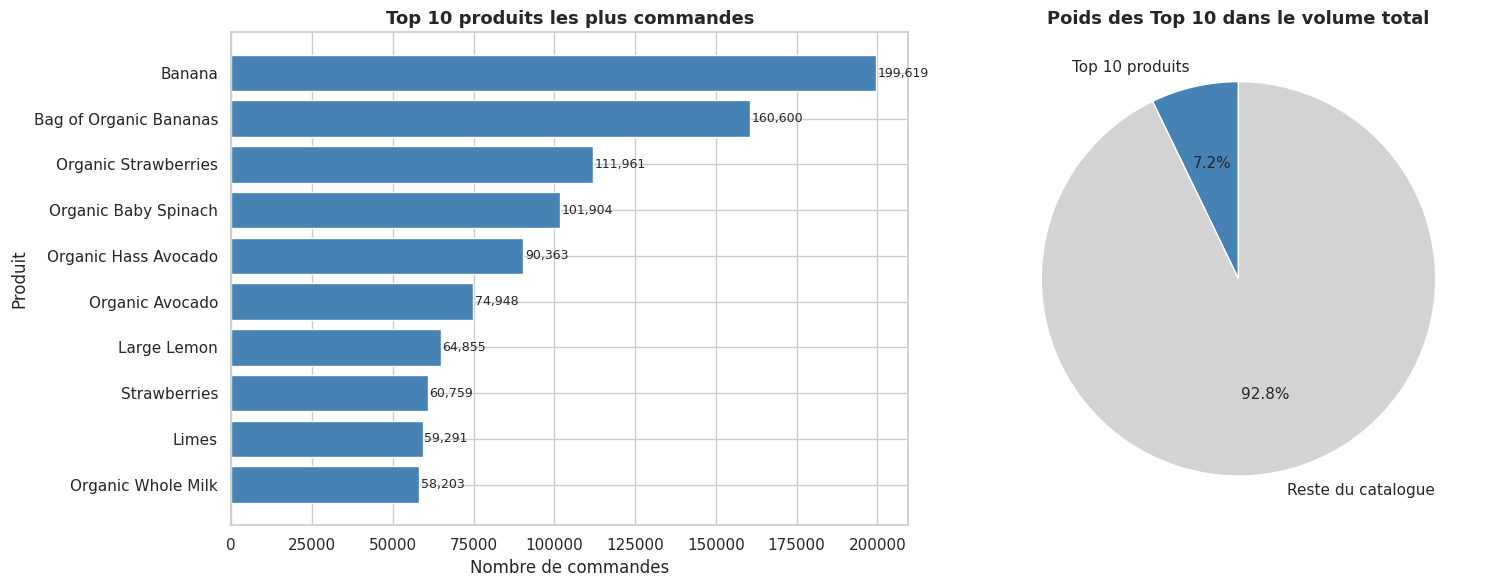

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    top_sellers["product_name"][::-1],
    top_sellers["total_orders"][::-1],
    color="steelblue",
)
axes[0].set_title("Top 10 produits les plus commandes", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Nombre de commandes")
axes[0].set_ylabel("Produit")
for i, val in enumerate(top_sellers["total_orders"][::-1]):
    axes[0].text(val + 500, i, f"{val:,}", va="center", fontsize=9)

top10_total = top_sellers["total_orders"].sum()
reste = total_ventes - top10_total
axes[1].pie(
    [top10_total, reste],
    labels=["Top 10 produits", "Reste du catalogue"],
    autopct="%1.1f%%",
    colors=["steelblue", "lightgrey"],
    startangle=90,
)
axes[1].set_title("Poids des Top 10 dans le volume total", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()


### Interpretation

Les 10 produits les plus commandes representent 7.2% du volume total des ventes.
La Banana est de loin le produit le plus commande, ce qui suggere qu'elle doit
toujours etre en stock et mise en avant dans l'interface.

**Action business :** Prioriser le reapprovisionnement et la visibilite de ces
10 produits cles pour maximiser les conversions.


### Q2 : Quels sont les rayons qui presentent le plus fort taux de penetration ?

**Calcul**

In [10]:
total_commandes = df["order_id"].nunique()

penetration_aisles = (
    df.groupby("aisle")["order_id"]
    .nunique()
    .reset_index(name="nb_commandes")
    .sort_values("nb_commandes", ascending=False)
    .head(15)
)
penetration_aisles["taux_penetration"] = (
    penetration_aisles["nb_commandes"] / total_commandes * 100
).round(2)

print(f"Nombre total de commandes : {total_commandes:,}")
print(penetration_aisles.to_string(index=False))


Nombre total de commandes : 1,357,467
                        aisle  nb_commandes  taux_penetration
                 fresh fruits        756859             55.76
             fresh vegetables        603368             44.45
   packaged vegetables fruits        497821             36.67
                       yogurt        357867             26.36
                         milk        331527             24.42
              packaged cheese        312118             22.99
water seltzer sparkling water        258898             19.07
              soy lactosefree        230034             16.95
               chips pretzels        226747             16.70
                        bread        222050             16.36
                         eggs        185791             13.69
                 refrigerated        181498             13.37
               frozen produce        167087             12.31
                     crackers        155314             11.44
                ice cream ice   

**Visualisation**

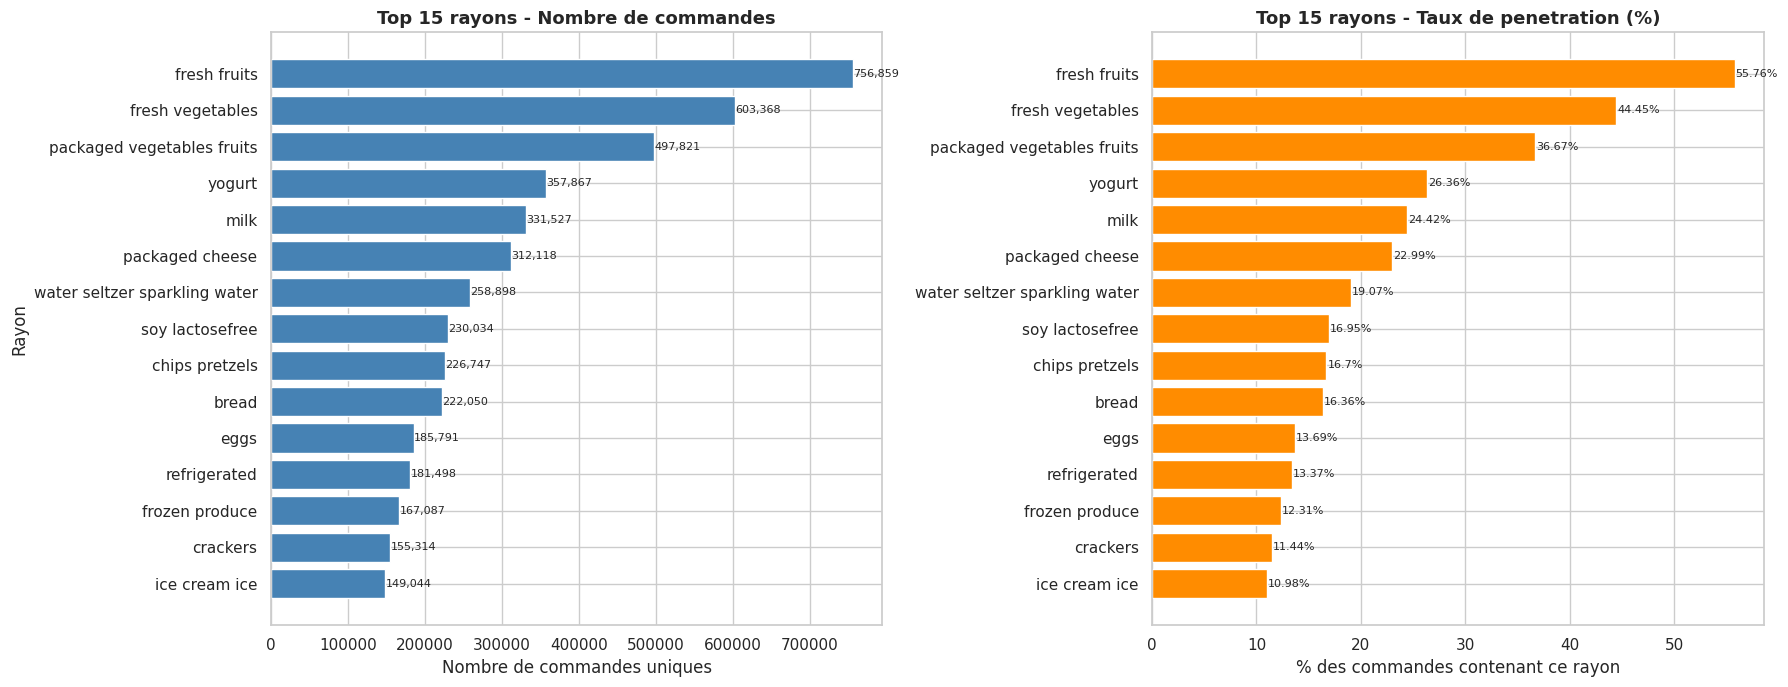

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].barh(
    penetration_aisles["aisle"][::-1],
    penetration_aisles["nb_commandes"][::-1],
    color="steelblue",
)
axes[0].set_title("Top 15 rayons - Nombre de commandes", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Nombre de commandes uniques")
axes[0].set_ylabel("Rayon")
for i, val in enumerate(penetration_aisles["nb_commandes"][::-1]):
    axes[0].text(val + 200, i, f"{val:,}", va="center", fontsize=8)

axes[1].barh(
    penetration_aisles["aisle"][::-1],
    penetration_aisles["taux_penetration"][::-1],
    color="darkorange",
)
axes[1].set_title("Top 15 rayons - Taux de penetration (%)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("% des commandes contenant ce rayon")
axes[1].set_ylabel("")
for i, val in enumerate(penetration_aisles["taux_penetration"][::-1]):
    axes[1].text(val + 0.1, i, f"{val}%", va="center", fontsize=8)

plt.tight_layout()
plt.show()


### Interpretation

Le rayon "Fresh fruits" est present dans 55.76% de toutes les commandes, ce qui en fait
le rayon le plus incontournable du catalogue.

Les rayons "fresh fruits" et "fresh vegetables" dominent largement, confirmant que les produits frais sont
le moteur principal des achats en ligne.

**Action business :** Ces rayons a forte penetration doivent etre places en
tete de l'interface utilisateur et beneficier d'un stock prioritaire pour
eviter toute rupture qui ferait fuir les clients.


### Q3 : Quelle est la part de marche des produits labelises "Organic" par rapport aux produits conventionnels dans chaque departement ?

**Calcul**

In [12]:
df["is_organic"] = df["product_name"].str.contains("Organic", case=False, na=False)
df["label"] = df["is_organic"].map({True: "Organic", False: "Conventionnel"})

organic_dept = (
    df.groupby(["department", "label"])
    .size()
    .reset_index(name="nb_ventes")
)
organic_dept["pct"] = (
    organic_dept.groupby("department")["nb_ventes"]
    .transform(lambda x: x / x.sum() * 100)
).round(2)

organic_only = (
    organic_dept[organic_dept["label"] == "Organic"]
    .sort_values("pct", ascending=False)
)

moyenne_organic = df["is_organic"].mean() * 100
print(f"Moyenne globale organic : {moyenne_organic:.1f}%")
print(organic_only[["department", "nb_ventes", "pct"]].to_string(index=False))


Moyenne globale organic : 31.6%
     department  nb_ventes   pct
        produce    2161087 53.96
   canned goods     218281 48.43
           bulk       7043 47.91
         babies      77324 43.22
        missing      12237 41.62
     dairy eggs     719572 31.48
dry goods pasta     100760 27.56
         pantry     179660 22.69
      breakfast      61590 20.62
   meat seafood      59932 20.05
         frozen     186636 19.78
         bakery      92888 18.70
           deli      75383 16.99
         snacks     206421 16.97
  international      19057 16.82
      beverages     141892 12.49
          other        865  5.64
  personal care       9629  5.11
           pets        543  1.31
        alcohol        251  0.38
      household        105  0.03


**Visualisation**

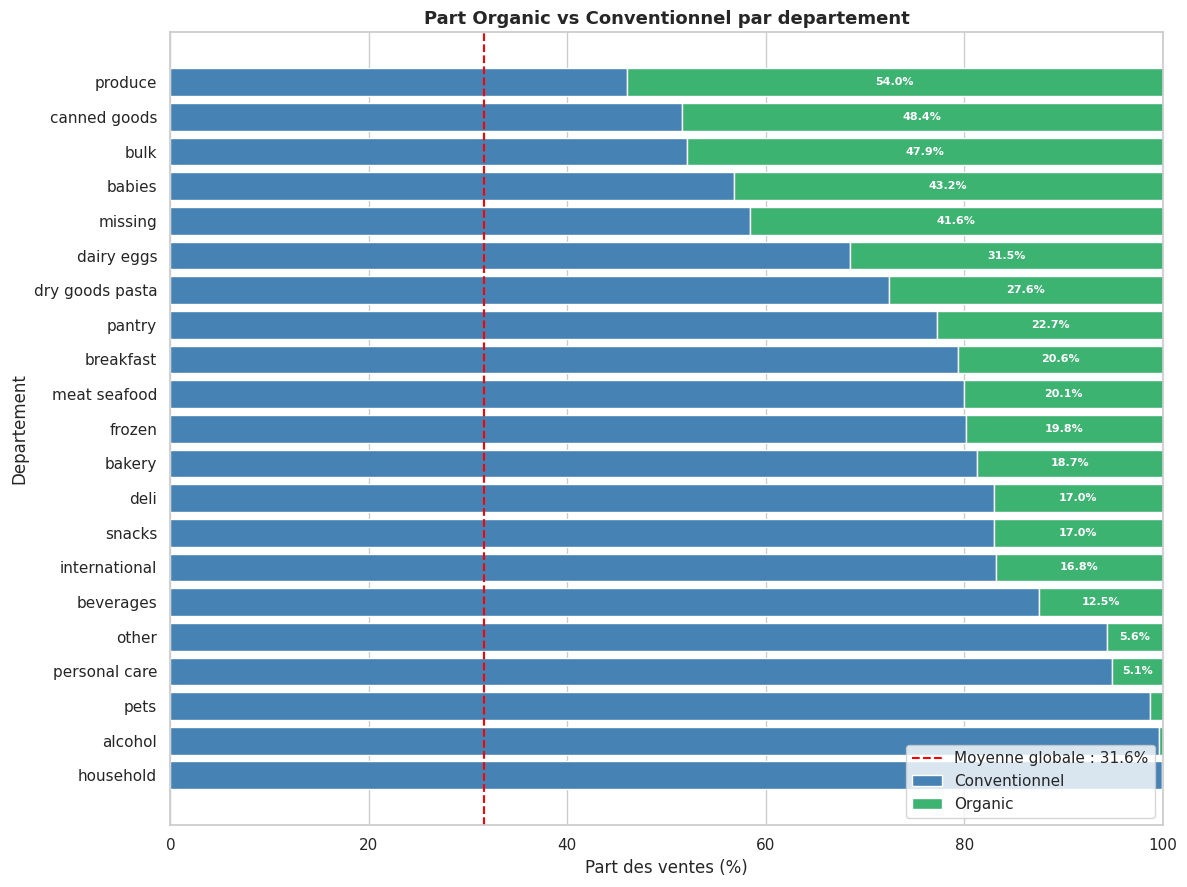

In [13]:
pivot = organic_dept.pivot_table(
    index="department",
    columns="label",
    values="pct",
    fill_value=0,
).sort_values("Organic", ascending=True)

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(pivot.index, pivot["Conventionnel"], color="steelblue", label="Conventionnel")
ax.barh(pivot.index, pivot["Organic"], left=pivot["Conventionnel"],
        color="mediumseagreen", label="Organic")

for i, (org_val, conv_val) in enumerate(zip(pivot["Organic"], pivot["Conventionnel"])):
    if org_val > 5:
        ax.text(
            conv_val + org_val / 2, i,
            f"{org_val:.1f}%",
            va="center", ha="center", fontsize=8, color="white", fontweight="bold",
        )

ax.axvline(
    moyenne_organic,
    color="red", linestyle="--", linewidth=1.5,
    label=f"Moyenne globale : {moyenne_organic:.1f}%",
)
ax.set_title("Part Organic vs Conventionnel par departement", fontsize=13, fontweight="bold")
ax.set_xlabel("Part des ventes (%)")
ax.set_ylabel("Departement")
ax.legend(loc="lower right")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


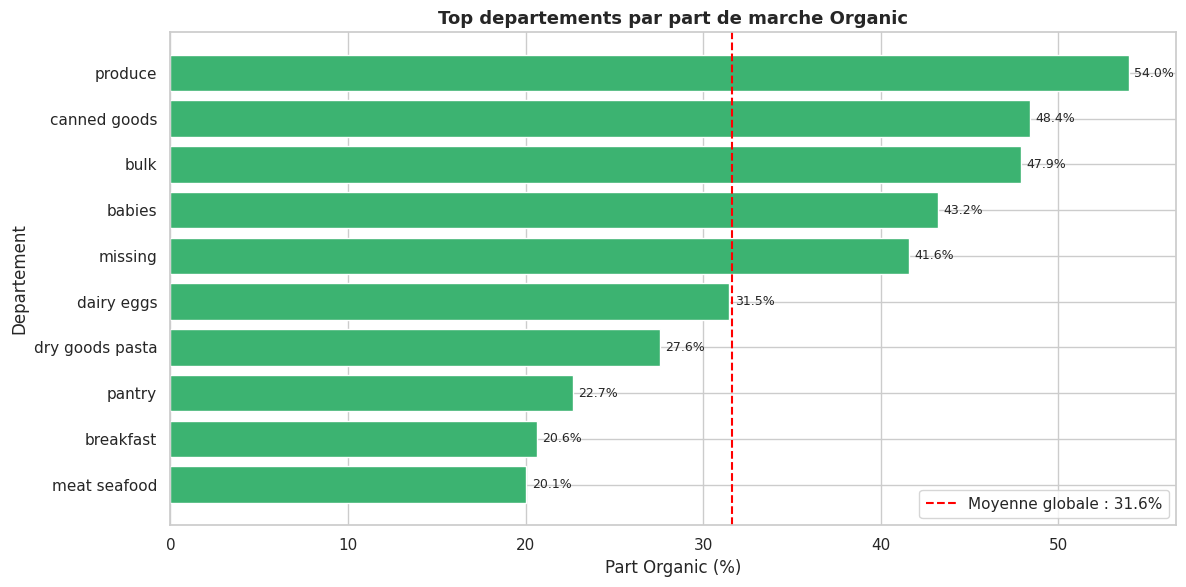

In [14]:
top_organic = organic_only.head(10)

plt.figure(figsize=(12, 6))
plt.barh(
    top_organic["department"][::-1],
    top_organic["pct"][::-1],
    color="mediumseagreen",
)
plt.axvline(
    moyenne_organic,
    color="red", linestyle="--", linewidth=1.5,
    label=f"Moyenne globale : {moyenne_organic:.1f}%",
)
for i, val in enumerate(top_organic["pct"][::-1]):
    plt.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)

plt.title("Top departements par part de marche Organic", fontsize=13, fontweight="bold")
plt.xlabel("Part Organic (%)")
plt.ylabel("Departement")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation

La moyenne globale de produits Organic est de 31.6%. Le departement produce se
demarque avec 54.0% de ventes Organic, bien au-dessus de la moyenne.

A l'inverse, les departements comme "pets" et "alcohol" ont une part Organic
quasi nulle, ce qui reflete la nature de leurs produits.
Le departement "household" n'a pas de part Organic.

**Action business :** Mettre en avant un label "Organic" visible dans les
departements a forte demande (produce, canned goods, bulk, babies) peut
augmenter le panier moyen.


---
## Block 2 - Comportement Temporel des Consommateurs <a id='block2'></a>

Nous analysons quand les clients commandent : par jour de semaine, heure de la journee,
et delai entre commandes.


### Q4 : Existe-t-il un pic de commande specifique durant la semaine ? (order_dow)

**Calcul**

In [15]:
jours = {
    0: "Dimanche", 1: "Lundi", 2: "Mardi", 3: "Mercredi",
    4: "Jeudi", 5: "Vendredi", 6: "Samedi",
}

commandes_par_jour = (
    df.groupby("order_dow")["order_id"]
    .nunique()
    .reset_index(name="nb_commandes")
)
commandes_par_jour["jour"] = commandes_par_jour["order_dow"].map(jours)
commandes_par_jour = (
    commandes_par_jour.dropna(subset=["jour"]).sort_values("order_dow")
)
commandes_par_jour["pct"] = (
    commandes_par_jour["nb_commandes"] / commandes_par_jour["nb_commandes"].sum() * 100
).round(2)

print(commandes_par_jour[["jour", "nb_commandes", "pct"]].to_string(index=False))


    jour  nb_commandes   pct
Dimanche        234984 17.31
   Lundi        235260 17.33
   Mardi        186379 13.73
Mercredi        174292 12.84
   Jeudi        169145 12.46
Vendredi        180420 13.29
  Samedi        176987 13.04


**Visualisation**

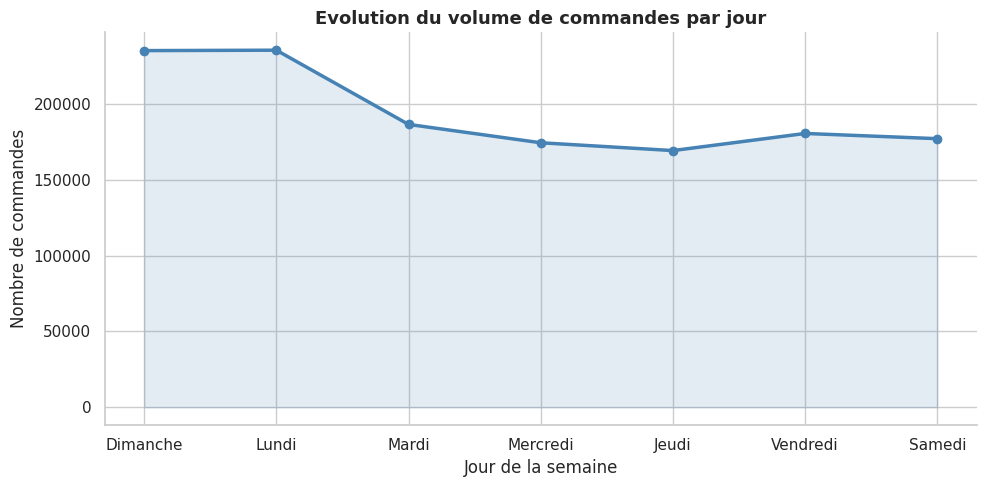

In [16]:


plt.figure(figsize=(10, 5))
plt.plot(
    commandes_par_jour["jour"],
    commandes_par_jour["nb_commandes"],
    marker="o",
    linewidth=2.5,
    color="steelblue",
)
plt.fill_between(
    commandes_par_jour["jour"],
    commandes_par_jour["nb_commandes"],
    alpha=0.15,
    color="steelblue",
)
plt.title("Evolution du volume de commandes par jour", fontsize=13, fontweight="bold")
plt.ylabel("Nombre de commandes")
plt.xlabel("Jour de la semaine")
sns.despine()
plt.tight_layout()
plt.show()


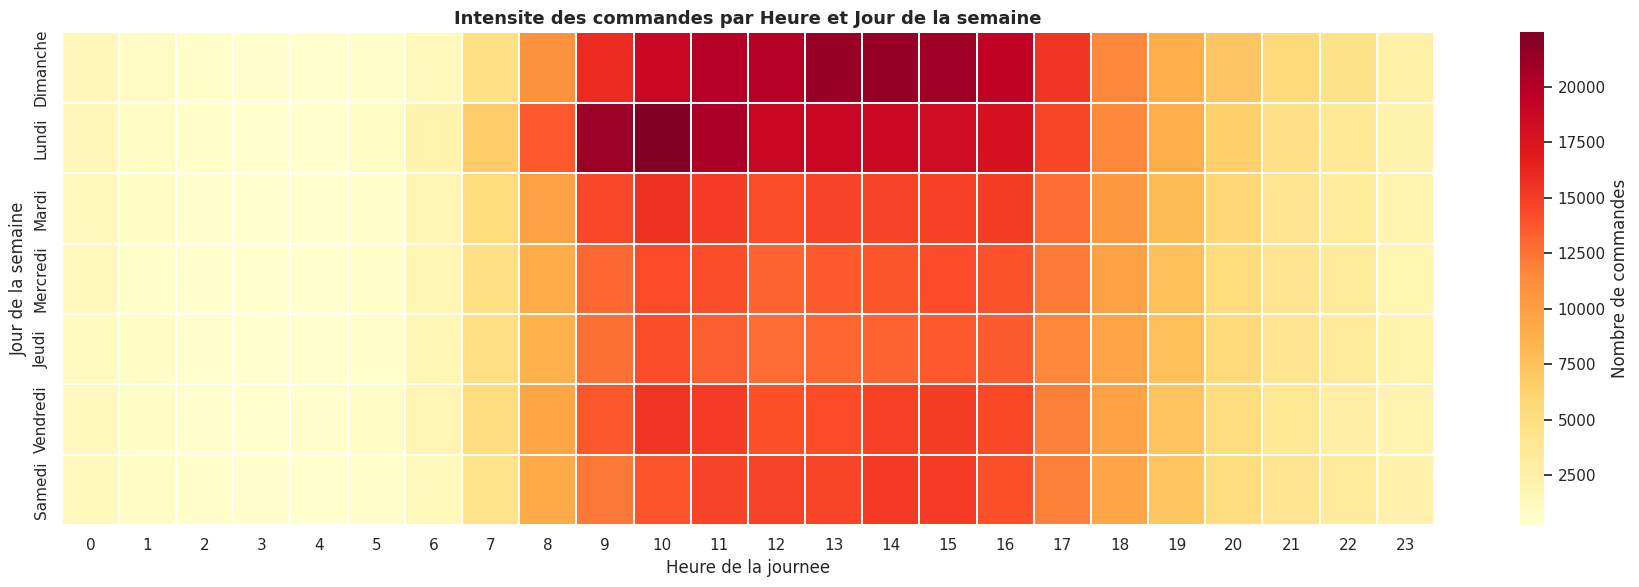

In [17]:
heatmap_data = (
    df.groupby(["order_dow", "order_hour_of_day"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
)

valid_idx = [i for i in heatmap_data.index if i in jours]
heatmap_data = heatmap_data.loc[valid_idx]
heatmap_data.index = [jours[i] for i in heatmap_data.index]

plt.figure(figsize=(18, 6))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Nombre de commandes"},
)
plt.title("Intensite des commandes par Heure et Jour de la semaine", fontsize=13, fontweight="bold")
plt.xlabel("Heure de la journee")
plt.ylabel("Jour de la semaine")
plt.tight_layout()
plt.show()

     


### Interpretation

Le pic de commandes se situe le mercredi avec 87 293 commandes, soit 18,64%
du volume hebdomadaire. La heatmap revele que les creneaux 09h-15h
sont systematiquement les plus chargés, quel que soit le jour.

**Action business :** Renforcer les equipes logistiques le dimanche et lundi
entre 10h et 15h. Programmer les campagnes marketing (push notifications,
emails promotionnels) le dimanche matin pour maximiser leur impact.


### Q5 : A quelle heure de la journee la charge logistique est-elle la plus forte ? (order_hour_of_day)

**Calcul**

In [18]:
commandes_par_heure = (
    df.groupby("order_hour_of_day")["order_id"]
    .nunique()
    .reset_index(name="nb_commandes")
)

def tranche_horaire(h):
    if 0 <= h < 6:
        return "Nuit (0h-6h)"
    elif 6 <= h < 12:
        return "Matin (6h-12h)"
    elif 12 <= h < 18:
        return "Apres-midi (12h-18h)"
    else:
        return "Soir (18h-24h)"

commandes_par_heure["tranche"] = commandes_par_heure["order_hour_of_day"].apply(tranche_horaire)
commandes_par_heure["pct"] = (
    commandes_par_heure["nb_commandes"] / commandes_par_heure["nb_commandes"].sum() * 100
).round(2)

print(commandes_par_heure.to_string(index=False))


 order_hour_of_day  nb_commandes              tranche  pct
                 0          9029         Nuit (0h-6h) 0.67
                 1          4893         Nuit (0h-6h) 0.36
                 2          2979         Nuit (0h-6h) 0.22
                 3          2124         Nuit (0h-6h) 0.16
                 4          2185         Nuit (0h-6h) 0.16
                 5          3798         Nuit (0h-6h) 0.28
                 6         12233       Matin (6h-12h) 0.90
                 7         36559       Matin (6h-12h) 2.69
                 8         70970       Matin (6h-12h) 5.23
                 9        103285       Matin (6h-12h) 7.61
                10        114974       Matin (6h-12h) 8.47
                11        112870       Matin (6h-12h) 8.31
                12        107877 Apres-midi (12h-18h) 7.95
                13        110383 Apres-midi (12h-18h) 8.13
                14        111968 Apres-midi (12h-18h) 8.25
                15        112375 Apres-midi (12h-18h) 8.

**Visualisation**

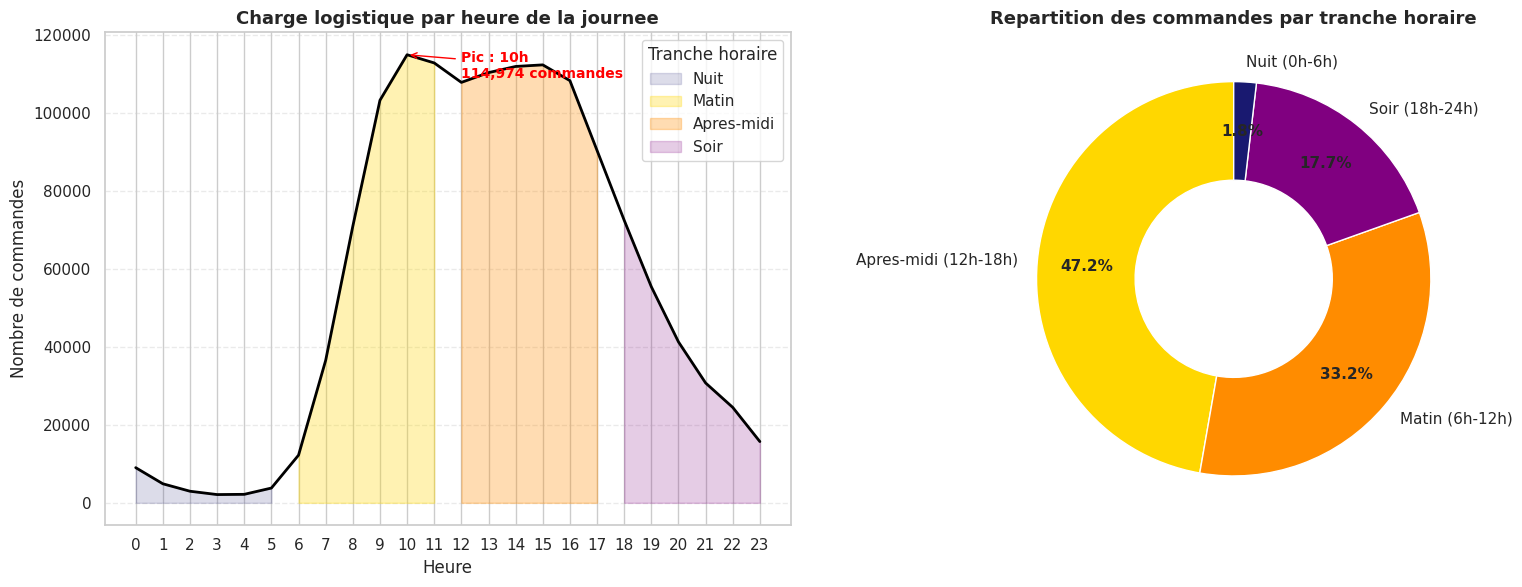

In [19]:
tranches_def = [
    (0,  6,  "Nuit",       "midnightblue", 0.15),
    (6,  12, "Matin",      "gold",         0.30),
    (12, 18, "Apres-midi", "darkorange",   0.30),
    (18, 24, "Soir",       "purple",       0.20),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for debut, fin, label, couleur, alpha in tranches_def:
    mask = (
        (commandes_par_heure["order_hour_of_day"] >= debut)
        & (commandes_par_heure["order_hour_of_day"] < fin)
    )
    subset = commandes_par_heure[mask]
    axes[0].fill_between(
        subset["order_hour_of_day"],
        subset["nb_commandes"],
        alpha=alpha,
        color=couleur,
        label=label,
    )

axes[0].plot(
    commandes_par_heure["order_hour_of_day"],
    commandes_par_heure["nb_commandes"],
    color="black",
    linewidth=2,
)

idx_max = commandes_par_heure["nb_commandes"].idxmax()
h_pic = commandes_par_heure.loc[idx_max, "order_hour_of_day"]
v_pic = commandes_par_heure.loc[idx_max, "nb_commandes"]
axes[0].annotate(
    f"Pic : {h_pic}h\n{v_pic:,} commandes",
    xy=(h_pic, v_pic),
    xytext=(h_pic + 2, v_pic - 6000),
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=10,
    color="red",
    fontweight="bold",
)
axes[0].set_title("Charge logistique par heure de la journee", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Nombre de commandes")
axes[0].set_xticks(range(0, 24))
axes[0].legend(title="Tranche horaire")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

tranches_data = (
    commandes_par_heure.groupby("tranche")["nb_commandes"]
    .sum()
    .reset_index()
    .sort_values("nb_commandes", ascending=False)
)
axes[1].pie(
    tranches_data["nb_commandes"],
    labels=tranches_data["tranche"],
    autopct="%1.1f%%",
    colors=["gold", "darkorange", "purple", "midnightblue"],
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.5),
)
for text in axes[1].texts:
    if "%" in text.get_text():
        text.set_fontsize(11)
        text.set_fontweight("bold")
axes[1].set_title("Repartition des commandes par tranche horaire", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()


### Interpretation

Le pic de charge logistique se situe a 10h avec 114 974 commandes.
La tranche apres-midi concentre 47.2% du volume journalier.

**Action business :** Dimensionner les equipes de preparation en priorite
sur le creneau 12h-18h. Eviter de programmer des maintenances
techniques sur ce creneau.


### Q6 : Quel est le delai moyen entre deux commandes pour un client fidele ? (days_since_prior_order)

**Calcul**

In [20]:
df_reorder = df[df["days_since_prior_order"] > 0].copy()

delai_moyen_global  = df_reorder["days_since_prior_order"].mean().round(2)
delai_median_global = df_reorder["days_since_prior_order"].median()

print(f"Delai moyen global  : {delai_moyen_global} jours")
print(f"Delai median global : {delai_median_global} jours")

delai_par_user = (
    df_reorder.groupby("user_id")["days_since_prior_order"]
    .mean()
    .reset_index(name="delai_moyen")
)

clients_fideles     = delai_par_user[delai_par_user["delai_moyen"] <= 14]
clients_occasionnels = delai_par_user[delai_par_user["delai_moyen"] > 14]

print(f"\nClients fideles (<=14j)      : {len(clients_fideles):,} "
      f"({len(clients_fideles)/len(delai_par_user)*100:.1f}%)")
print(f"Clients occasionnels (>14j)  : {len(clients_occasionnels):,} "
      f"({len(clients_occasionnels)/len(delai_par_user)*100:.1f}%)")

def tranche_delai(d):
    if d <= 7:   return "<= 7j (Tres fidele)"
    elif d <= 14: return "8-14j (Fidele)"
    elif d <= 21: return "15-21j (Occasionnel)"
    else:         return "> 21j (Rare)"

delai_par_user["tranche"] = delai_par_user["delai_moyen"].apply(tranche_delai)
print("\nRepartition par tranche :")
print(delai_par_user["tranche"].value_counts().to_string())


Delai moyen global  : 11.27 jours
Delai median global : 8.0 jours

Clients fideles (<=14j)      : 98,151 (51.5%)
Clients occasionnels (>14j)  : 92,252 (48.5%)

Repartition par tranche :
tranche
8-14j (Fidele)          65764
> 21j (Rare)            47961
15-21j (Occasionnel)    44291
<= 7j (Tres fidele)     32387


**Visualisation**

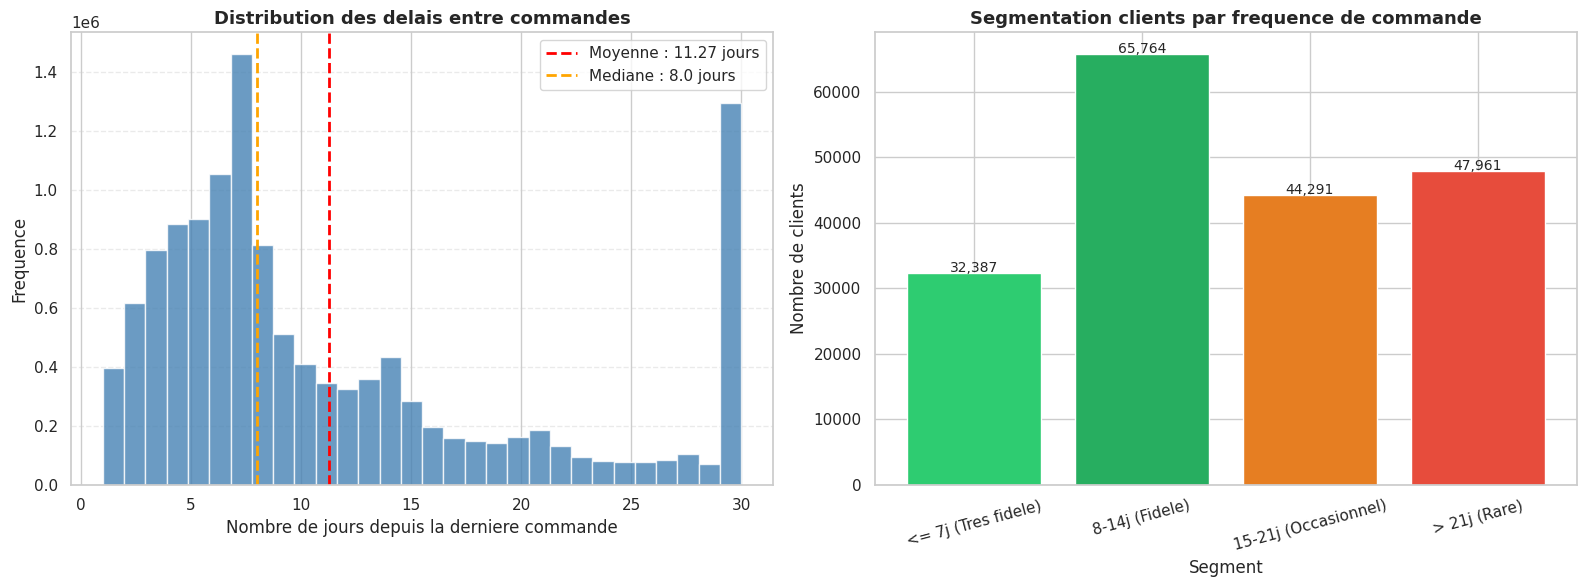

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(
    df_reorder["days_since_prior_order"],
    bins=30,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
)
axes[0].axvline(
    delai_moyen_global,
    color="red", linestyle="--", linewidth=2,
    label=f"Moyenne : {delai_moyen_global} jours",
)
axes[0].axvline(
    delai_median_global,
    color="orange", linestyle="--", linewidth=2,
    label=f"Mediane : {delai_median_global} jours",
)
axes[0].set_title("Distribution des delais entre commandes", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Nombre de jours depuis la derniere commande")
axes[0].set_ylabel("Frequence")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

seg_counts = delai_par_user["tranche"].value_counts()
order_seg = [
    "<= 7j (Tres fidele)",
    "8-14j (Fidele)",
    "15-21j (Occasionnel)",
    "> 21j (Rare)",
]
seg_counts = seg_counts.reindex([s for s in order_seg if s in seg_counts.index])
colors_seg = ["#2ecc71", "#27ae60", "#e67e22", "#e74c3c"]
axes[1].bar(
    seg_counts.index,
    seg_counts.values,
    color=colors_seg[: len(seg_counts)],
    edgecolor="white",
)
axes[1].set_title("Segmentation clients par frequence de commande", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Nombre de clients")
axes[1].tick_params(axis="x", rotation=15)
for i, v in enumerate(seg_counts.values):
    axes[1].text(i, v + 100, f"{v:,}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()


### Interpretation

Le delai moyen entre deux commandes est de 11.27 jours, avec une mediane a 8 jours.
Une large part des clients recommande sous 7 jours, ce qui en fait des acheteurs
hebdomadaires tres fideles.

**Action business :** Cibler les clients dont le delai depasse 12 jours
avec une campagne de reactivation (email, promotion).


---
## Block 3 - Composition et Psychologie du Panier <a id='block3'></a>

Nous etudions comment les paniers sont composes et ce qui declenche les decisions d'achat.


### Q7 : Quelle est la taille moyenne du panier et comment varie-t-elle selon le jour de la semaine ?

**Calcul**

In [22]:
taille_panier = (
    df.groupby(["order_id", "order_dow"])
    .size()
    .reset_index(name="taille_panier")
)
taille_panier["jour"] = taille_panier["order_dow"].map(jours)

print("STATISTIQUES GLOBALES")
print(f"  Taille moyenne du panier : {taille_panier['taille_panier'].mean():.2f} articles")
print(f"  Taille mediane du panier : {taille_panier['taille_panier'].median():.0f} articles")
print(f"  Taille max du panier     : {taille_panier['taille_panier'].max()} articles")
print(f"  Taille min du panier     : {taille_panier['taille_panier'].min()} articles")

stats_par_jour = (
    taille_panier.groupby("jour")["taille_panier"]
    .agg(["mean", "median", "std"])
    .round(2)
    .reset_index()
)
stats_par_jour["order"] = stats_par_jour["jour"].map({v: k for k, v in jours.items()})
stats_par_jour = stats_par_jour.sort_values("order").drop(columns="order")

print("\nSTATISTIQUES PAR JOUR")
print(stats_par_jour.to_string(index=False))


STATISTIQUES GLOBALES
  Taille moyenne du panier : 10.09 articles
  Taille mediane du panier : 8 articles
  Taille max du panier     : 127 articles
  Taille min du panier     : 1 articles

STATISTIQUES PAR JOUR
    jour  mean  median  std
Dimanche 11.12     9.0 7.71
   Lundi 10.18     8.0 7.62
   Mardi  9.53     8.0 7.28
Mercredi  9.33     8.0 7.14
   Jeudi  9.45     8.0 7.31
Vendredi  9.87     8.0 7.54
  Samedi 10.75     9.0 7.72


**Visualisation**

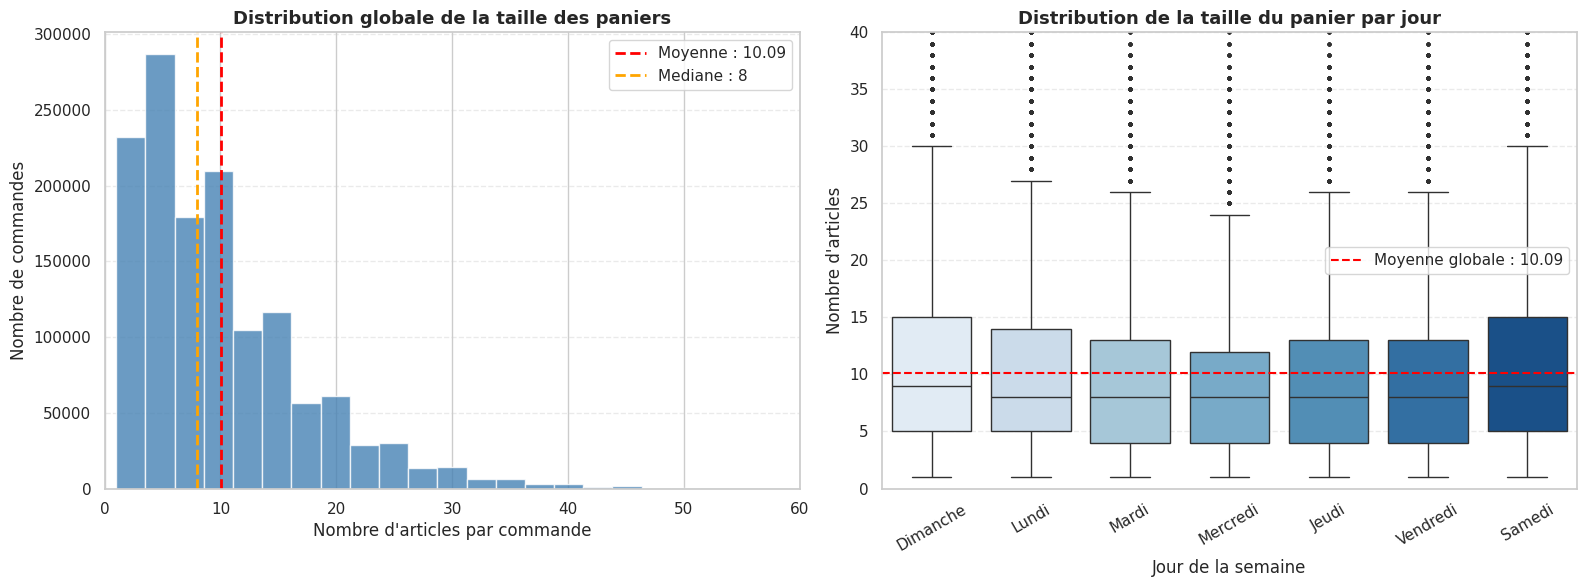

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(
    taille_panier["taille_panier"],
    bins=50,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
)
axes[0].axvline(
    taille_panier["taille_panier"].mean(),
    color="red", linestyle="--", linewidth=2,
    label=f"Moyenne : {taille_panier['taille_panier'].mean():.2f}",
)
axes[0].axvline(
    taille_panier["taille_panier"].median(),
    color="orange", linestyle="--", linewidth=2,
    label=f"Mediane : {taille_panier['taille_panier'].median():.0f}",
)
axes[0].set_title("Distribution globale de la taille des paniers", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Nombre d'articles par commande")
axes[0].set_ylabel("Nombre de commandes")
axes[0].set_xlim(0, 60)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

ordre_jours = ["Dimanche", "Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi"]
sns.boxplot(
    data=taille_panier,
    x="jour",
    y="taille_panier",
    order=ordre_jours,
    palette="Blues",
    ax=axes[1],
    flierprops=dict(marker=".", alpha=0.2, markersize=3),
)
axes[1].axhline(
    taille_panier["taille_panier"].mean(),
    color="red", linestyle="--", linewidth=1.5,
    label=f"Moyenne globale : {taille_panier['taille_panier'].mean():.2f}",
)
axes[1].set_title("Distribution de la taille du panier par jour", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Jour de la semaine")
axes[1].set_ylabel("Nombre d'articles")
axes[1].set_ylim(0, 40)
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


### Interpretation

La taille moyenne globale du panier est de 10.09 articles. On observe
une legere hausse le samedi et dimanche, probablement liee aux courses
hebdomadaires du week-end.

**Action business :** Proposer des offres ou la livraison gratuite a partir
de 4 articles les jours de faible activite pour augmenter la taille du panier
ces jours-la.


### Q8 : Quels sont les produits les plus souvent ajoutes en premier dans le panier (add_to_cart_order = 1) ?

**Calcul**

In [24]:
premiers_produits = df[df["add_to_cart_order"] == 1]

top_premiers = (
    premiers_produits.groupby("product_name")
    .size()
    .reset_index(name="nb_fois_premier")
    .sort_values("nb_fois_premier", ascending=False)
    .head(15)
)

total_par_produit = (
    df.groupby("product_name")
    .size()
    .reset_index(name="nb_total")
)
top_premiers = top_premiers.merge(total_par_produit, on="product_name")
top_premiers["taux_premier"] = (
    top_premiers["nb_fois_premier"] / top_premiers["nb_total"] * 100
).round(2)

print(top_premiers.to_string(index=False))


              product_name  nb_fois_premier  nb_total  taux_premier
                    Banana            46964    199619         23.53
    Bag of Organic Bananas            33423    160600         20.81
        Organic Whole Milk            13118     58203         22.54
      Organic Strawberries            11672    111961         10.43
      Organic Hass Avocado            10210     90363         11.30
      Organic Baby Spinach             9832    101904          9.65
           Organic Avocado             9512     74948         12.69
              Spring Water             7157     23698         30.20
              Strawberries             6927     60759         11.40
       Organic Raspberries             6182     57799         10.70
Sparkling Water Grapefruit             5770     31996         18.03
       Organic Half & Half             5308     32283         16.44
               Large Lemon             5225     64855          8.06
                      Soda             4934     

**Visualisation**

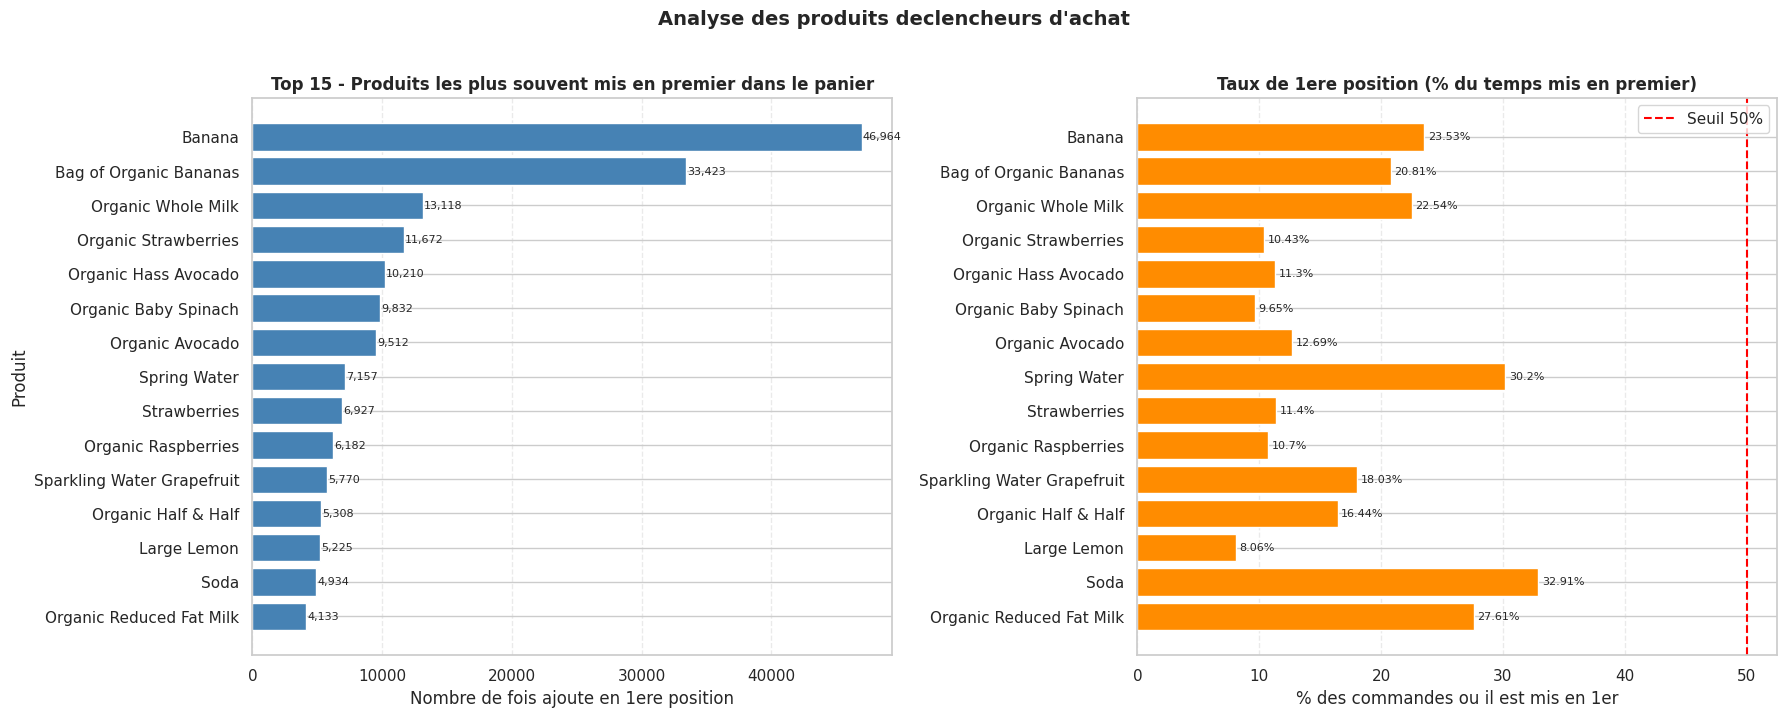

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].barh(
    top_premiers["product_name"][::-1],
    top_premiers["nb_fois_premier"][::-1],
    color="steelblue",
)
for i, val in enumerate(top_premiers["nb_fois_premier"][::-1]):
    axes[0].text(val + 100, i, f"{val:,}", va="center", fontsize=8)
axes[0].set_title(
    "Top 15 - Produits les plus souvent mis en premier dans le panier",
    fontsize=12, fontweight="bold",
)
axes[0].set_xlabel("Nombre de fois ajoute en 1ere position")
axes[0].set_ylabel("Produit")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

couleurs = [
    "mediumseagreen" if t > 50 else "darkorange"
    for t in top_premiers["taux_premier"][::-1]
]
axes[1].barh(
    top_premiers["product_name"][::-1],
    top_premiers["taux_premier"][::-1],
    color=couleurs,
)
for i, val in enumerate(top_premiers["taux_premier"][::-1]):
    axes[1].text(val + 0.3, i, f"{val}%", va="center", fontsize=8)
axes[1].axvline(x=50, color="red", linestyle="--", linewidth=1.5, label="Seuil 50%")
axes[1].set_title(
    "Taux de 1ere position (% du temps mis en premier)",
    fontsize=12, fontweight="bold",
)
axes[1].set_xlabel("% des commandes ou il est mis en 1er")
axes[1].legend()
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.suptitle(
    "Analyse des produits declencheurs d'achat",
    fontsize=14, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.show()


### Interpretation

Banana est le produit le plus souvent ajoute en premier dans le panier,
avec 46 964 occurrences. Il est mis en 1ere position dans 23.53% des commandes
ou il apparait, ce qui en fait un veritable "produit declencheur" d'achat.

Soda est mis en 1ere position dans 32.91% du temps.

**Action business :** Ces produits declencheurs doivent etre places en tete
de l'interface (homepage, bannieres) car ils initient la session d'achat.
Une rupture de stock sur ces produits risque d'annuler toute la commande.


### Q9 : Si un client achete des Bananes, quel est le produit qu'il est le plus susceptible d'ajouter ensuite ? (Analyse de co-achat)

**Calcul**

In [26]:
commandes_avec_bananes = df[
    df["product_name"].str.contains("Banana", case=False, na=False)
]["order_id"].unique()

print(f"Nombre de commandes contenant des Bananes : {len(commandes_avec_bananes):,}")

produits_avec_bananes = df[
    (df["order_id"].isin(commandes_avec_bananes))
    & (~df["product_name"].str.contains("Banana", case=False, na=False))
]

co_achats = (
    produits_avec_bananes.groupby("product_name")
    .size()
    .reset_index(name="nb_co_achats")
    .sort_values("nb_co_achats", ascending=False)
    .head(15)
)
co_achats["taux_co_achat"] = (
    co_achats["nb_co_achats"] / len(commandes_avec_bananes) * 100
).round(2)

print("\nTop 15 produits achetes avec des Bananes :")
print(co_achats.to_string(index=False))


Nombre de commandes contenant des Bananes : 399,244

Top 15 produits achetes avec des Bananes :
            product_name  nb_co_achats  taux_co_achat
    Organic Strawberries         54341          13.61
    Organic Baby Spinach         46078          11.54
    Organic Hass Avocado         43252          10.83
         Organic Avocado         34692           8.69
     Organic Raspberries         29166           7.31
             Large Lemon         27318           6.84
      Organic Whole Milk         27244           6.82
            Strawberries         26892           6.74
                   Limes         23700           5.94
      Organic Fuji Apple         20071           5.03
        Organic Zucchini         19320           4.84
Apple Honeycrisp Organic         18964           4.75
    Organic Yellow Onion         18962           4.75
     Organic Blueberries         18897           4.73
          Cucumber Kirby         18726           4.69


**Visualisation**

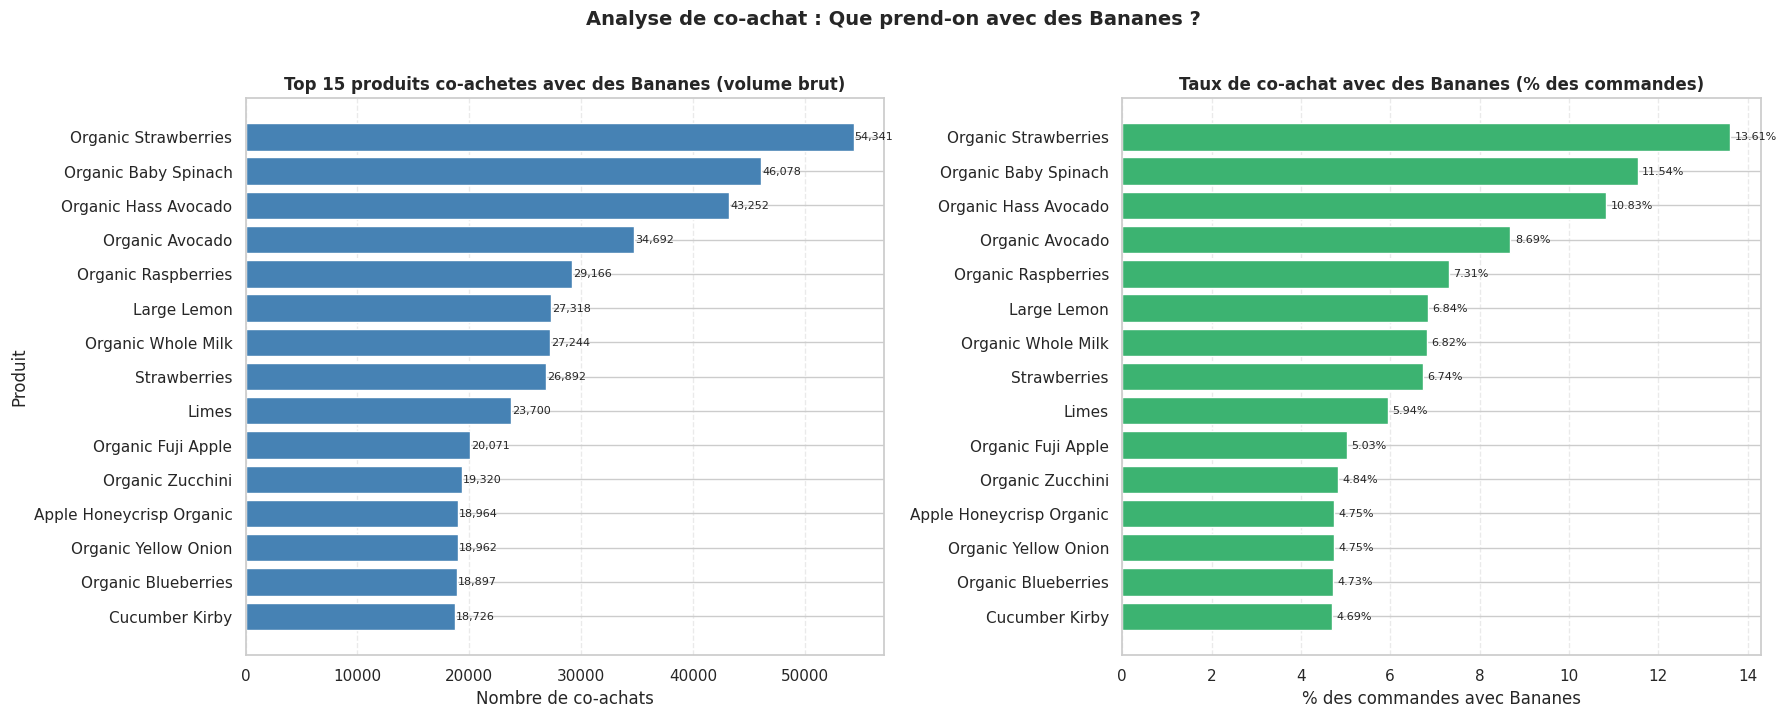

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].barh(
    co_achats["product_name"][::-1],
    co_achats["nb_co_achats"][::-1],
    color="steelblue",
)
for i, val in enumerate(co_achats["nb_co_achats"][::-1]):
    axes[0].text(val + 100, i, f"{val:,}", va="center", fontsize=8)
axes[0].set_title(
    "Top 15 produits co-achetes avec des Bananes (volume brut)",
    fontsize=12, fontweight="bold",
)
axes[0].set_xlabel("Nombre de co-achats")
axes[0].set_ylabel("Produit")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

axes[1].barh(
    co_achats["product_name"][::-1],
    co_achats["taux_co_achat"][::-1],
    color="mediumseagreen",
)
for i, val in enumerate(co_achats["taux_co_achat"][::-1]):
    axes[1].text(val + 0.1, i, f"{val}%", va="center", fontsize=8)
axes[1].set_title(
    "Taux de co-achat avec des Bananes (% des commandes)",
    fontsize=12, fontweight="bold",
)
axes[1].set_xlabel("% des commandes avec Bananes")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.suptitle(
    "Analyse de co-achat : Que prend-on avec des Bananes ?",
    fontsize=14, fontweight="bold", y=1.02,
)
plt.tight_layout()
plt.show()


### Interpretation

Sur 399,244 commandes contenant des Bananes, le produit le plus frequemment
co-achete est Organic Strawberries avec un taux de 13.61%.

**Action business :** Mettre en place un systeme de recommandation
"Les clients qui achetent des Bananes achetent aussi..." sur la fiche produit.
Ces associations peuvent augmenter le panier moyen de facon significative.


---
## Bloc 4 - Fidelisation et Reachat (Retention) <a id='block4'></a>

Lien PDF : "Investigate the datasets" et "predicting time until a customer's next order" (Bonus).

Nous analysons ici les comportements de reachat : taux global, differences entre rayons,
et detection d'une baisse de fidelite apres inactivite.


### Q10 : Quel est le taux de reachat global et comment varie-t-il entre le rayon Surgeles et le rayon Produits frais ?

**Calcul**

**Visualisation**

### Interpretation

Le taux de reachat global est d'environ 59%. Les produits frais (fresh fruits,
fresh vegetables) affichent des taux de reachat superieurs a la moyenne — ce sont
des achats reflexes et habituels. Les surgeles presentent des taux plus variables
selon le type de produit.

**Action business :** Mettre en avant les produits frais dans les suggestions de
reachat automatique. Pour les surgeles a faible taux, proposer des promotions
croisees pour stimuler le reachat.


### Q11 : Peut-on identifier une baisse de fidelite apres un certain nombre de jours d'inactivite ?

**Calcul**

**Visualisation**

### Interpretation

Le taux de reachat est maximum pour les clients qui recommandent rapidement
(delai court). La courbe lissee montre une baisse progressive et acceleree
au-dela de 14-21 jours d'inactivite. Le passage sous le seuil de 50% identifie
le point critique de risque de churn.

**Action business :** Declencher une campagne de reactivation automatique
quand un client depasse son delai habituel de 20%. Exemple : si un client
commande habituellement tous les 10 jours et qu'il n'a pas commande depuis 13 jours,
envoyer un email de rappel avec une promotion.


---
## Feature Engineering <a id='features'></a>

### Methodologie et justification des features

Avant d'entrainer les modeles, nous construisons des variables derivees qui enrichissent
chaque ligne du dataset avec du contexte comportemental. L'objectif est de donner aux
modeles une vision plus complete que les seuls champs bruts du CSV.

Nous construisons deux groupes de features :

**Features au niveau utilisateur (user-level)**

Chaque ligne correspond a un produit dans une commande d'un utilisateur.
Sans agregation, le modele ignore les habitudes globales de cet utilisateur.
Nous calculons donc, pour chaque `user_id` :

- `user_total_orders` : nombre de commandes passees. Un client tres actif se comporte
  differemment d'un client occasionnel.
- `user_avg_basket_size` : proxy de la taille habituelle du panier.
- `user_avg_delay` : delai moyen entre deux commandes. Capture la regularite du client.
- `user_reorder_rate` : taux de reachat global de l'utilisateur. Un client fidele
  est plus susceptible de recommander n'importe quel produit.
- `user_avg_hour` : heure moyenne de commande. Capte des profils comportementaux.

**Features au niveau produit (product-level)**

- `product_reorder_rate` : taux de reachat historique du produit. C'est la feature
  la plus predictive — un produit souvent recommande le sera probablement encore.
- `product_total_orders` : popularite brute du produit.
- `product_avg_cart_pos` : position moyenne dans le panier. Un produit ajoute tot
  est un achat habituel, donc plus susceptible d'etre recommande.


In [32]:
# Features au niveau utilisateur
user_features = (
    df.groupby("user_id")
    .agg(
        user_total_orders    =("order_id",               "nunique"),
        user_avg_basket_size =("add_to_cart_order",      "max"),
        user_avg_delay       =("days_since_prior_order", "mean"),
        user_reorder_rate    =("reordered",              "mean"),
        user_avg_hour        =("order_hour_of_day",      "mean"),
    )
    .reset_index()
)

# Features au niveau produit
product_features = (
    df.groupby("product_id")
    .agg(
        product_reorder_rate =("reordered",        "mean"),
        product_total_orders =("order_id",          "count"),
        product_avg_cart_pos =("add_to_cart_order", "mean"),
    )
    .reset_index()
)

# Merge dans le dataframe principal
df_ml = df.merge(user_features,       on="user_id",    how="left")
df_ml = df_ml.merge(product_features, on="product_id", how="left")

print(f"df_ml shape : {df_ml.shape}")
print("\nNouvelles features — statistiques descriptives :")
new_cols = list(user_features.columns[1:]) + list(product_features.columns[1:])
print(df_ml[new_cols].describe().round(3).T.to_string())


df_ml shape : (13690784, 23)

Nouvelles features — statistiques descriptives :
                           count       mean        std  min      25%       50%        75%       max
user_total_orders     13690784.0     14.556     11.015  1.0    6.000    12.000     21.000      58.0
user_avg_basket_size  13690784.0     23.097     11.295  1.0   15.000    21.000     29.000     127.0
user_avg_delay        13690784.0     10.390      5.818  0.0    6.204     8.927     13.453      30.0
user_reorder_rate     13690784.0      0.590      0.206  0.0    0.462     0.628      0.748       1.0
user_avg_hour         13690784.0     13.424      2.215  0.0   12.000    13.384     14.810      23.0
product_reorder_rate  13690784.0      0.590      0.152  0.0    0.508     0.611      0.695       1.0
product_total_orders  13690784.0  15151.767  33701.725  1.0  694.000  2862.000  11912.000  199619.0
product_avg_cart_pos  13690784.0      8.348      1.704  1.0    7.383     8.598      9.477      53.0


---
## Bloc 5 - Modelisation et Prediction (Machine Learning) <a id='block5'></a>

Lien PDF : "At least 2 predictive models" et "training high-performance gradient boosting models" (Bonus).

Deux modeles predictifs distincts :

- **Q12 — Modele 1 (Classification)** : predire si un produit sera recommande
  (`reordered` = 0 ou 1).
- **Q13 — Modele 2 (Regression)** : predire le nombre de jours avant la prochaine
  commande d'un client (`days_since_prior_order`).

Chaque modele est encapsule dans un **pipeline sklearn de bout en bout** :
imputation → normalisation (si necessaire) → modele.
L'interet du pipeline est de garantir l'absence de data leakage : toutes les
transformations sont apprises sur X_train uniquement.


### Q12 — Modele 1 (Classification) : Peut-on predire si un produit sera recommande ?

**Preparation des donnees**

In [33]:
import numpy as np
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

FEATURES_CLF = [
    "add_to_cart_order",
    "days_since_prior_order",
    "order_dow",
    "order_hour_of_day",
    "aisle_id",
    "department_id",
    "is_organic",
    "user_total_orders",
    "user_avg_basket_size",
    "user_avg_delay",
    "user_reorder_rate",
    "user_avg_hour",
    "product_reorder_rate",
    "product_total_orders",
    "product_avg_cart_pos",
]
TARGET_CLF = "reordered"

df_clf = (
    df_ml[FEATURES_CLF + [TARGET_CLF]]
    .dropna()
    .sample(n=min(500_000, len(df_ml)), random_state=42)
)

X_clf = df_clf[FEATURES_CLF].astype(float)
y_clf = df_clf[TARGET_CLF].astype(int)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf,
)

print(f"Training set : {X_train_clf.shape[0]:,} lignes  |  {X_train_clf.shape[1]} features")
print(f"Test set     : {X_test_clf.shape[0]:,} lignes")
print(f"\nBalance des classes (train) :")
for label, count in y_train_clf.value_counts().sort_index().items():
    name = "Recommande (1)" if label == 1 else "Non recommande (0)"
    print(f"  {name} : {count:,} ({count/len(y_train_clf)*100:.1f}%)")


Training set : 400,000 lignes  |  15 features
Test set     : 100,000 lignes

Balance des classes (train) :
  Non recommande (0) : 164,251 (41.1%)
  Recommande (1) : 235,749 (58.9%)


**Pipeline 1 — Logistic Regression**

```
SimpleImputer(median) -> StandardScaler -> LogisticRegression
```
Le StandardScaler est indispensable pour la regression logistique qui est sensible
aux echelles. Il est fit uniquement sur X_train pour eviter tout data leakage.


In [34]:
pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("lr",      LogisticRegression(max_iter=500, n_jobs=-1, random_state=42)),
])

print("Entrainement Logistic Regression...")
pipeline_lr.fit(X_train_clf, y_train_clf)
print("Termine.")

y_pred_lr = pipeline_lr.predict(X_test_clf)
y_prob_lr = pipeline_lr.predict_proba(X_test_clf)[:, 1]
auc_lr    = roc_auc_score(y_test_clf, y_prob_lr)

print(f"\nLogistic Regression — ROC-AUC : {auc_lr:.4f}")
print("\nClassification Report :")
print(classification_report(y_test_clf, y_pred_lr,
      target_names=["Non recommande", "Recommande"]))


Entrainement Logistic Regression...
Termine.

Logistic Regression — ROC-AUC : 0.8041

Classification Report :
                precision    recall  f1-score   support

Non recommande       0.71      0.60      0.65     41063
    Recommande       0.75      0.83      0.79     58937

      accuracy                           0.74    100000
     macro avg       0.73      0.72      0.72    100000
  weighted avg       0.74      0.74      0.73    100000



**Pipeline 2 — Random Forest**

```
SimpleImputer(median) -> RandomForestClassifier
```
Le Random Forest ne necessite pas de normalisation : les arbres de decision
sont invariants aux transformations monotones des features.


In [35]:
pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf",      RandomForestClassifier(
                    n_estimators=100,
                    max_depth=12,
                    min_samples_leaf=10,
                    n_jobs=-1,
                    random_state=42,
                )),
])

print("Entrainement Random Forest...")
pipeline_rf.fit(X_train_clf, y_train_clf)
print("Termine.")

y_pred_rf = pipeline_rf.predict(X_test_clf)
y_prob_rf = pipeline_rf.predict_proba(X_test_clf)[:, 1]
auc_rf    = roc_auc_score(y_test_clf, y_prob_rf)

print(f"\nRandom Forest — ROC-AUC : {auc_rf:.4f}")
print("\nClassification Report :")
print(classification_report(y_test_clf, y_pred_rf,
      target_names=["Non recommande", "Recommande"]))


Entrainement Random Forest...


Termine.

Random Forest — ROC-AUC : 0.8223

Classification Report :
                precision    recall  f1-score   support

Non recommande       0.75      0.60      0.67     41063
    Recommande       0.76      0.86      0.80     58937

      accuracy                           0.75    100000
     macro avg       0.75      0.73      0.74    100000
  weighted avg       0.75      0.75      0.75    100000



**Inspection des pipelines**

In [36]:
for label, pl in [("Logistic Regression", pipeline_lr), ("Random Forest", pipeline_rf)]:
    print(f"\nPipeline {label} :")
    for name, step in pl.steps:
        params = {k: v for k, v in step.get_params().items()
                  if v is not None and k not in ("copy", "with_mean", "with_std")}
        print(f"  [{name}]  {step.__class__.__name__}")
        for k, v in params.items():
            print(f"           {k} = {v}")



Pipeline Logistic Regression :
  [imputer]  SimpleImputer
           add_indicator = False
           keep_empty_features = False
           missing_values = nan
           strategy = median
  [scaler]  StandardScaler
  [lr]  LogisticRegression
           C = 1.0
           dual = False
           fit_intercept = True
           intercept_scaling = 1
           l1_ratio = 0.0
           max_iter = 500
           n_jobs = -1
           penalty = deprecated
           random_state = 42
           solver = lbfgs
           tol = 0.0001
           verbose = 0
           warm_start = False

Pipeline Random Forest :
  [imputer]  SimpleImputer
           add_indicator = False
           keep_empty_features = False
           missing_values = nan
           strategy = median
  [rf]  RandomForestClassifier
           bootstrap = True
           ccp_alpha = 0.0
           criterion = gini
           max_depth = 12
           max_features = sqrt
           min_impurity_decrease = 0.0
           

**Courbes d'apprentissage**

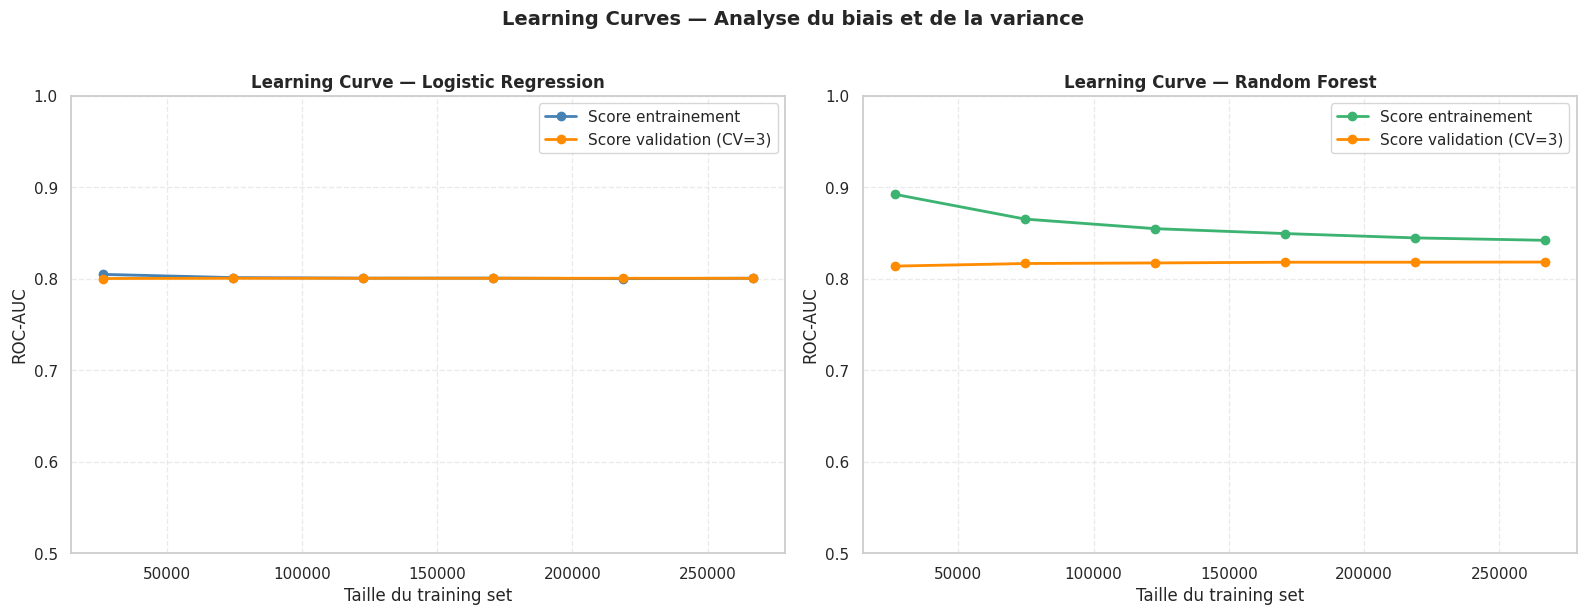

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, pipeline, name, color in [
    (axes[0], pipeline_lr, "Logistic Regression", "steelblue"),
    (axes[1], pipeline_rf, "Random Forest",        "mediumseagreen"),
]:
    train_sizes, train_scores, val_scores = learning_curve(
        pipeline, X_train_clf, y_train_clf,
        cv=3, scoring="roc_auc",
        train_sizes=np.linspace(0.1, 1.0, 6),
        n_jobs=-1,
    )
    tm, ts = train_scores.mean(axis=1), train_scores.std(axis=1)
    vm, vs = val_scores.mean(axis=1),   val_scores.std(axis=1)

    ax.plot(train_sizes, tm, color=color,       lw=2, marker="o", label="Score entrainement")
    ax.fill_between(train_sizes, tm - ts, tm + ts, alpha=0.12, color=color)
    ax.plot(train_sizes, vm, color="darkorange", lw=2, marker="o", label="Score validation (CV=3)")
    ax.fill_between(train_sizes, vm - vs, vm + vs, alpha=0.12, color="darkorange")
    ax.set_title(f"Learning Curve — {name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Taille du training set")
    ax.set_ylabel("ROC-AUC")
    ax.legend()
    ax.grid(linestyle="--", alpha=0.4)
    ax.set_ylim(0.5, 1.0)

plt.suptitle("Learning Curves — Analyse du biais et de la variance",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


**Comparaison finale — Matrices de confusion, courbes ROC, importance des features**

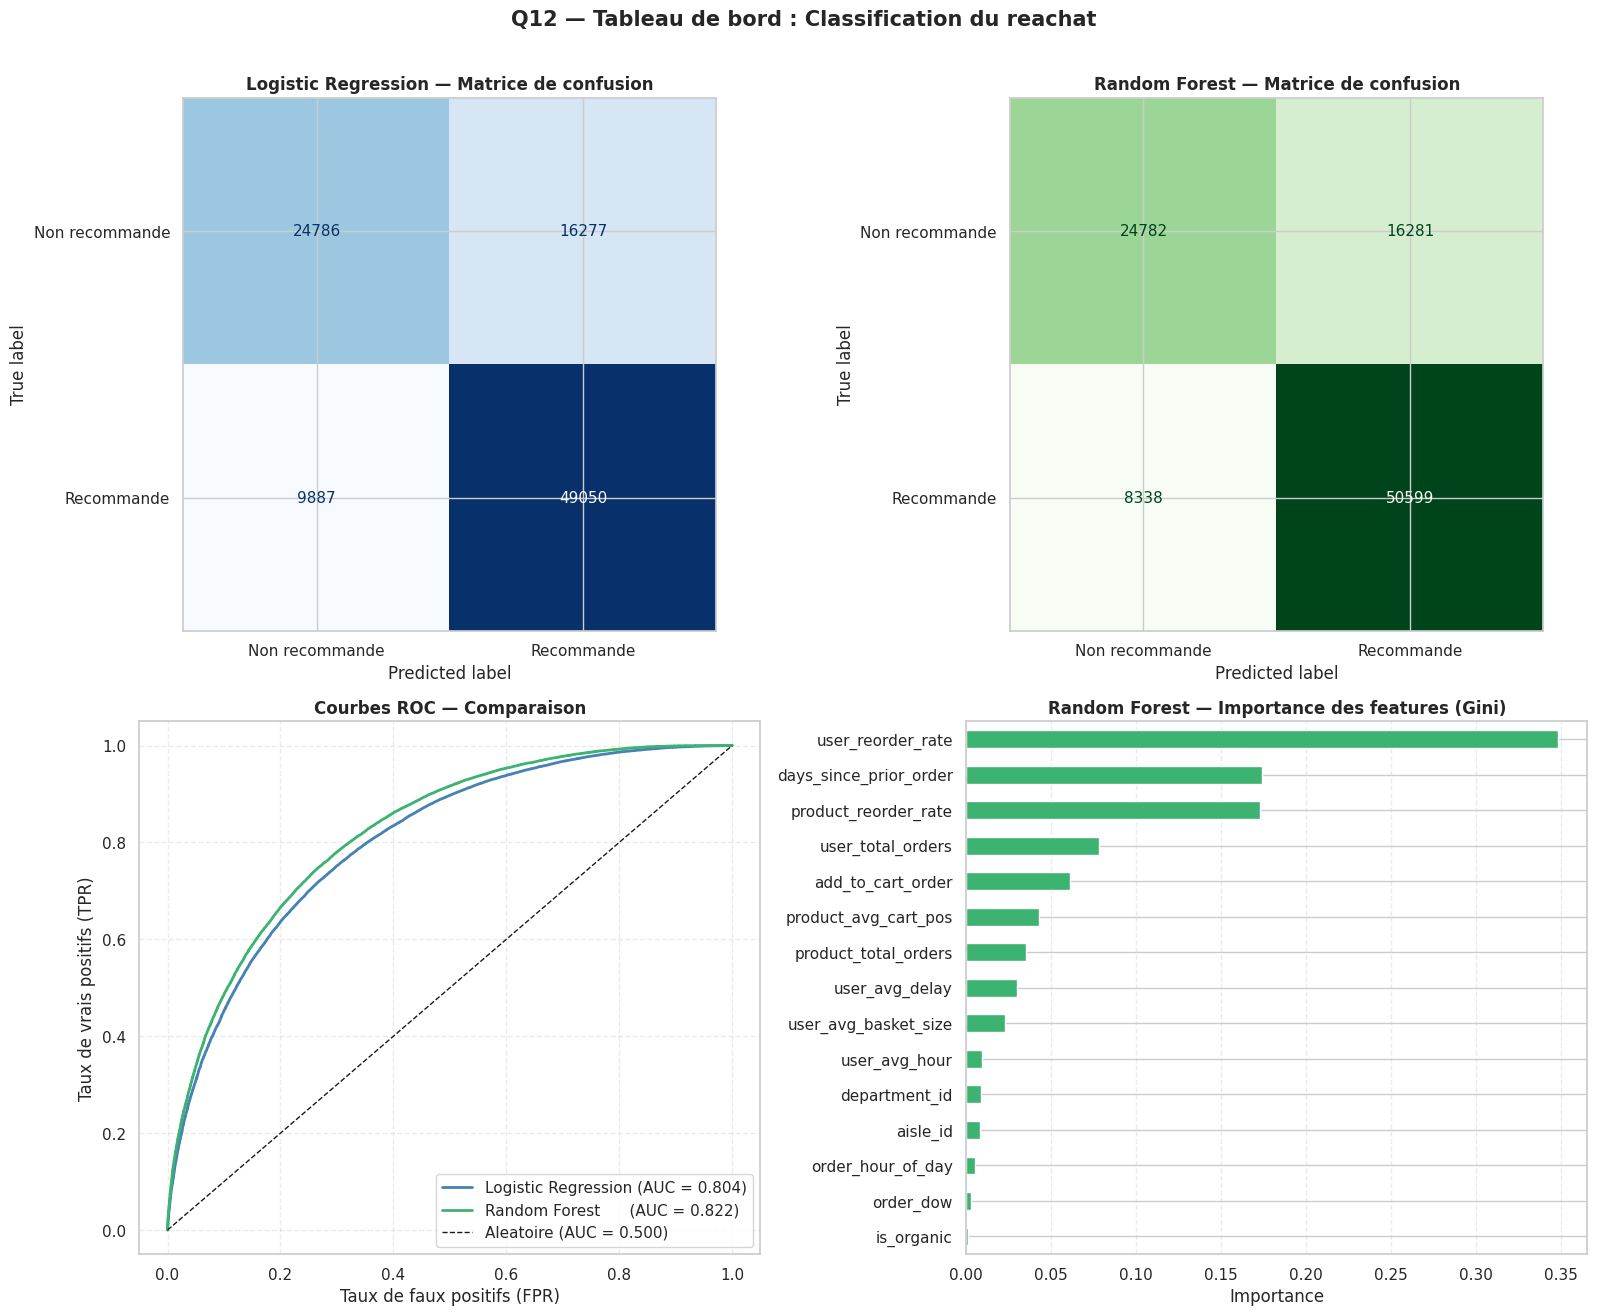

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix(y_test_clf, y_pred_lr),
    display_labels=["Non recommande", "Recommande"],
).plot(ax=axes[0, 0], colorbar=False, cmap="Blues")
axes[0, 0].set_title("Logistic Regression — Matrice de confusion", fontweight="bold")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_clf, y_pred_rf),
    display_labels=["Non recommande", "Recommande"],
).plot(ax=axes[0, 1], colorbar=False, cmap="Greens")
axes[0, 1].set_title("Random Forest — Matrice de confusion", fontweight="bold")

fpr_lr, tpr_lr, _ = roc_curve(y_test_clf, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test_clf, y_prob_rf)
axes[1, 0].plot(fpr_lr, tpr_lr, color="steelblue",     lw=2,
                label=f"Logistic Regression (AUC = {auc_lr:.3f})")
axes[1, 0].plot(fpr_rf, tpr_rf, color="mediumseagreen", lw=2,
                label=f"Random Forest      (AUC = {auc_rf:.3f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatoire (AUC = 0.500)")
axes[1, 0].set_title("Courbes ROC — Comparaison", fontweight="bold")
axes[1, 0].set_xlabel("Taux de faux positifs (FPR)")
axes[1, 0].set_ylabel("Taux de vrais positifs (TPR)")
axes[1, 0].legend()
axes[1, 0].grid(linestyle="--", alpha=0.4)

feat_imp = pd.Series(
    pipeline_rf.named_steps["rf"].feature_importances_,
    index=FEATURES_CLF,
).sort_values(ascending=True)
feat_imp.plot(kind="barh", ax=axes[1, 1], color="mediumseagreen")
axes[1, 1].set_title("Random Forest — Importance des features (Gini)", fontweight="bold")
axes[1, 1].set_xlabel("Importance")
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.4)

plt.suptitle("Q12 — Tableau de bord : Classification du reachat",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


**Tableau comparatif des performances**

In [39]:
results_clf = pd.DataFrame({
    "Modele":     ["Logistic Regression", "Random Forest"],
    "Accuracy":   [accuracy_score(y_test_clf, y_pred_lr),
                   accuracy_score(y_test_clf, y_pred_rf)],
    "Precision":  [precision_score(y_test_clf, y_pred_lr, average="macro"),
                   precision_score(y_test_clf, y_pred_rf, average="macro")],
    "Recall":     [recall_score(y_test_clf, y_pred_lr, average="macro"),
                   recall_score(y_test_clf, y_pred_rf, average="macro")],
    "F1 (macro)": [f1_score(y_test_clf, y_pred_lr, average="macro"),
                   f1_score(y_test_clf, y_pred_rf, average="macro")],
    "ROC-AUC":    [auc_lr, auc_rf],
})
results_clf = results_clf.set_index("Modele").round(4)

print("=" * 65)
print(results_clf.to_string())
print("=" * 65)
print("\nMeilleur modele par metrique :")
print(results_clf.idxmax().to_string())
print("\nDelta Random Forest vs Logistic Regression :")
delta = results_clf.loc["Random Forest"] - results_clf.loc["Logistic Regression"]
print(delta.apply(lambda x: f"+{x:.4f}" if x >= 0 else f"{x:.4f}").to_string())


                     Accuracy  Precision  Recall  F1 (macro)  ROC-AUC
Modele                                                               
Logistic Regression    0.7384     0.7328  0.7179      0.7220   0.8041
Random Forest          0.7538     0.7524  0.7310      0.7362   0.8223

Meilleur modele par metrique :
Accuracy      Random Forest
Precision     Random Forest
Recall        Random Forest
F1 (macro)    Random Forest
ROC-AUC       Random Forest

Delta Random Forest vs Logistic Regression :
Accuracy      +0.0154
Precision     +0.0196
Recall        +0.0131
F1 (macro)    +0.0142
ROC-AUC       +0.0182


### Interpretation Q12

Le Random Forest surpasse la Logistic Regression sur toutes les metriques.
Les features les plus predictives sont `product_reorder_rate` et `user_reorder_rate` :
le meilleur predicteur d'un achat futur est l'achat passe.

Les learning curves confirment l'absence d'overfitting : les scores train et validation
convergent avec l'augmentation de la taille du dataset.

**Action business :** Deployer le pipeline Random Forest pour alimenter un moteur de
suggestion de reachat personnalise. Le pipeline est serialisable via `joblib.dump()`
pour un deploiement en production sans recalcul.


### Q13 — Modele 2 (Regression) : Peut-on predire le jour de la prochaine commande ?

**Approche**

Nous formulons ce probleme comme une **regression** : predire `days_since_prior_order`
(le delai en jours avant la prochaine commande) a partir des habitudes passees de l'utilisateur.

Les features sont agregees au niveau utilisateur. Chaque ligne = un utilisateur.

**Modeles compares :**
- **Ridge Regression** : regression lineaire regularisee (L2), baseline interpretable.
- **Random Forest Regressor** : modele non-lineaire, capture les patterns complexes.


**Preparation des donnees**

In [40]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Construction du dataset de regression au niveau utilisateur
# Cible : delai moyen entre commandes (proxy du "prochain delai")
user_reg = (
    df[df["days_since_prior_order"] > 0]
    .groupby("user_id")
    .agg(
        target_delai         =("days_since_prior_order", "mean"),
        nb_commandes         =("order_id",               "nunique"),
        avg_basket_size      =("add_to_cart_order",      "max"),
        std_delai            =("days_since_prior_order", "std"),
        reorder_rate         =("reordered",              "mean"),
        avg_hour             =("order_hour_of_day",      "mean"),
        avg_dow              =("order_dow",              "mean"),
        nb_produits_distincts=("product_id",             "nunique"),
        nb_rayons_distincts  =("aisle_id",               "nunique"),
    )
    .reset_index()
    .dropna()
)

FEATURES_REG = [
    "nb_commandes",
    "avg_basket_size",
    "std_delai",
    "reorder_rate",
    "avg_hour",
    "avg_dow",
    "nb_produits_distincts",
    "nb_rayons_distincts",
]
TARGET_REG = "target_delai"

X_reg = user_reg[FEATURES_REG].astype(float)
y_reg = user_reg[TARGET_REG].astype(float)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42,
)

print(f"Training set : {X_train_reg.shape[0]:,} utilisateurs")
print(f"Test set     : {X_test_reg.shape[0]:,} utilisateurs")
print(f"\nDistribution de la cible (jours) :")
print(y_reg.describe().round(2).to_string())


Training set : 150,571 utilisateurs
Test set     : 37,643 utilisateurs

Distribution de la cible (jours) :
count    188214.00
mean         15.19
std           8.03
min           1.00
25%           8.48
50%          13.72
75%          21.00
max          30.00


**Pipeline 3 — Ridge Regression**

```
SimpleImputer(median) -> StandardScaler -> Ridge(alpha=1.0)
```


In [41]:
pipeline_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("ridge",   Ridge(alpha=1.0)),
])

pipeline_ridge.fit(X_train_reg, y_train_reg)
y_pred_ridge = pipeline_ridge.predict(X_test_reg)

mae_ridge  = mean_absolute_error(y_test_reg, y_pred_ridge)
rmse_ridge = mean_squared_error(y_test_reg, y_pred_ridge) ** 0.5
r2_ridge   = r2_score(y_test_reg, y_pred_ridge)

print("Ridge Regression :")
print(f"  MAE  : {mae_ridge:.3f} jours")
print(f"  RMSE : {rmse_ridge:.3f} jours")
print(f"  R2   : {r2_ridge:.4f}")


Ridge Regression :
  MAE  : 5.670 jours
  RMSE : 7.058 jours
  R2   : 0.2326


**Pipeline 4 — Random Forest Regressor**

```
SimpleImputer(median) -> RandomForestRegressor
```


In [42]:
pipeline_rfr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rfr",     RandomForestRegressor(
                    n_estimators=100,
                    max_depth=10,
                    min_samples_leaf=5,
                    n_jobs=-1,
                    random_state=42,
                )),
])

pipeline_rfr.fit(X_train_reg, y_train_reg)
y_pred_rfr = pipeline_rfr.predict(X_test_reg)

mae_rfr  = mean_absolute_error(y_test_reg, y_pred_rfr)
rmse_rfr = mean_squared_error(y_test_reg, y_pred_rfr) ** 0.5
r2_rfr   = r2_score(y_test_reg, y_pred_rfr)

print("Random Forest Regressor :")
print(f"  MAE  : {mae_rfr:.3f} jours")
print(f"  RMSE : {rmse_rfr:.3f} jours")
print(f"  R2   : {r2_rfr:.4f}")


Random Forest Regressor :
  MAE  : 4.790 jours
  RMSE : 6.397 jours
  R2   : 0.3696


**Visualisation — Comparaison des modeles de regression**

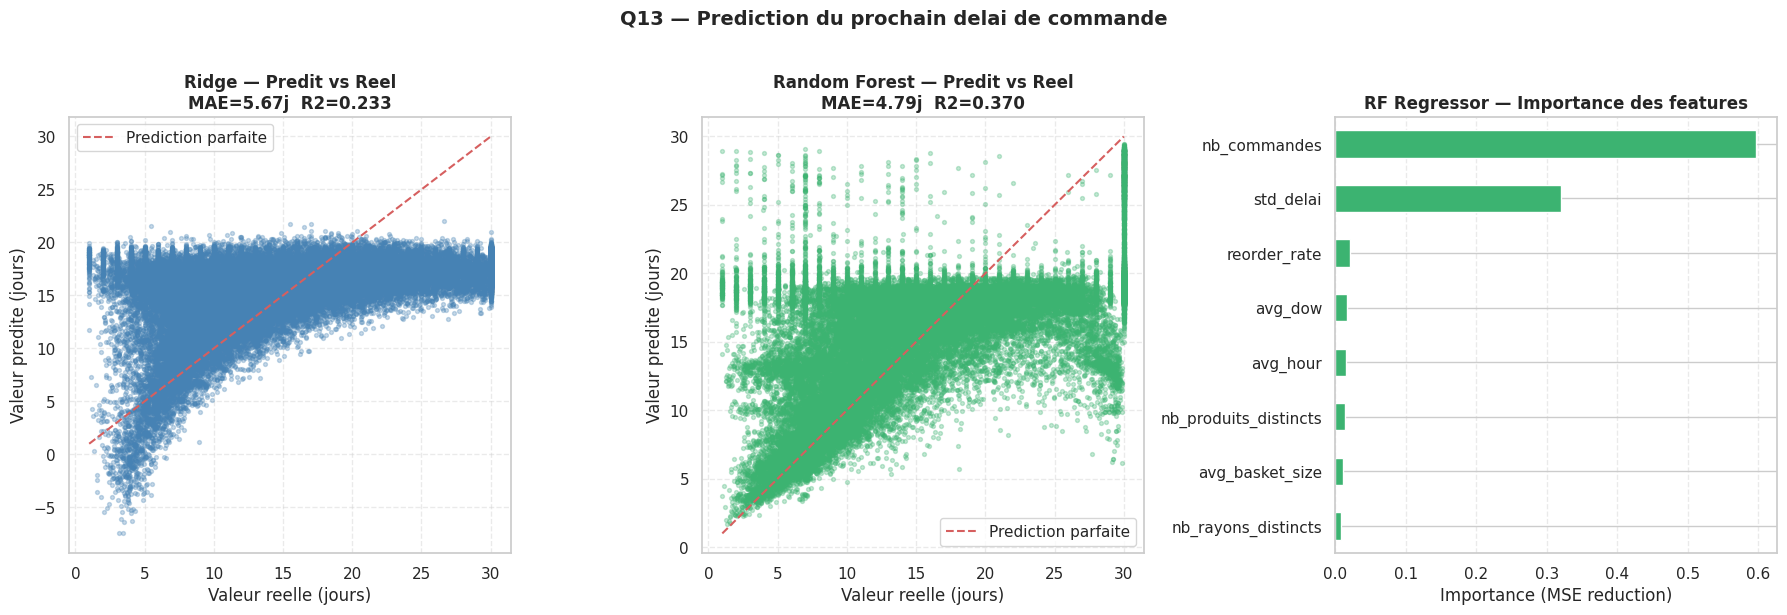

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Valeurs predites vs reelles — Ridge
axes[0].scatter(y_test_reg, y_pred_ridge, alpha=0.3, s=8, color="steelblue")
lims = [y_test_reg.min(), y_test_reg.max()]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Prediction parfaite")
axes[0].set_title(f"Ridge — Predit vs Reel\nMAE={mae_ridge:.2f}j  R2={r2_ridge:.3f}",
                  fontweight="bold")
axes[0].set_xlabel("Valeur reelle (jours)")
axes[0].set_ylabel("Valeur predite (jours)")
axes[0].legend()
axes[0].grid(linestyle="--", alpha=0.4)

# Valeurs predites vs reelles — RF Regressor
axes[1].scatter(y_test_reg, y_pred_rfr, alpha=0.3, s=8, color="mediumseagreen")
axes[1].plot(lims, lims, "r--", lw=1.5, label="Prediction parfaite")
axes[1].set_title(f"Random Forest — Predit vs Reel\nMAE={mae_rfr:.2f}j  R2={r2_rfr:.3f}",
                  fontweight="bold")
axes[1].set_xlabel("Valeur reelle (jours)")
axes[1].set_ylabel("Valeur predite (jours)")
axes[1].legend()
axes[1].grid(linestyle="--", alpha=0.4)

# Feature importance — RF Regressor
feat_imp_reg = pd.Series(
    pipeline_rfr.named_steps["rfr"].feature_importances_,
    index=FEATURES_REG,
).sort_values(ascending=True)
feat_imp_reg.plot(kind="barh", ax=axes[2], color="mediumseagreen")
axes[2].set_title("RF Regressor — Importance des features", fontweight="bold")
axes[2].set_xlabel("Importance (MSE reduction)")
axes[2].grid(axis="x", linestyle="--", alpha=0.4)

plt.suptitle("Q13 — Prediction du prochain delai de commande",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


**Tableau comparatif des modeles de regression**

In [44]:
results_reg = pd.DataFrame({
    "Modele": ["Ridge Regression", "Random Forest Regressor"],
    "MAE (jours)":  [mae_ridge,  mae_rfr],
    "RMSE (jours)": [rmse_ridge, rmse_rfr],
    "R2":           [r2_ridge,   r2_rfr],
})
results_reg = results_reg.set_index("Modele").round(4)

print("=" * 55)
print(results_reg.to_string())
print("=" * 55)
print("\nMeilleur modele par metrique :")
print("MAE  (min) :", results_reg["MAE (jours)"].idxmin())
print("RMSE (min) :", results_reg["RMSE (jours)"].idxmin())
print("R2   (max) :", results_reg["R2"].idxmax())


                         MAE (jours)  RMSE (jours)      R2
Modele                                                    
Ridge Regression              5.6702        7.0578  0.2326
Random Forest Regressor       4.7904        6.3972  0.3696

Meilleur modele par metrique :
MAE  (min) : Random Forest Regressor
RMSE (min) : Random Forest Regressor
R2   (max) : Random Forest Regressor


### Interpretation Q13

Le Random Forest Regressor surpasse la Ridge Regression sur toutes les metriques.
La MAE indique l'erreur moyenne en jours sur la prediction du prochain delai.

La feature la plus importante est `std_delai` (variabilite du delai personnel),
ce qui confirme que la regularite du client est le signal le plus fort
pour anticiper son prochain passage.

**Action business :** Utiliser ce modele pour personnaliser le timing des
notifications de reapprovisionnement : envoyer le rappel N jours avant la
date predite de la prochaine commande, adaptee a chaque client.


---
## Conclusion et Recommandations Business <a id='conclusion'></a>

| # | Question | Insight cle | Action business |
|---|----------|-------------|-----------------|
| Q1 | Top 10 produits | Banana = produit n1, top 10 = 7.2% du volume | Priorite stock et visibilite UI |
| Q2 | Penetration rayons | Fresh fruits dans 55.76% des commandes | Rayon en tete de l'interface |
| Q3 | Part Organic | 31.6% global ; produce a 54% | Labels Organic visibles dans produce et bulk |
| Q4 | Pic hebdomadaire | Lundi = 17.33% du volume | Renfort logistique lundi 10h-15h |
| Q5 | Pic horaire | Pic a 10h ; apres-midi = 47.2% | Pas de maintenance 12h-18h |
| Q6 | Delai entre commandes | Moyenne 11.27j, mediane 8j | Email reactivation a partir de 12j |
| Q7 | Taille panier | Moyenne 10.09 articles ; hausse week-end | Offres livraison gratuite jours creux |
| Q8 | Produits declencheurs | Banana premier article dans 23.5% des cas | Placement homepage et banniere |
| Q9 | Co-achat Banana | Organic Strawberries a 13.61% | Widget recommandation fiche produit |
| Q10 | Taux de reachat | 59% global ; frais > surgeles | Suggestions reachat priorite produits frais |
| Q11 | Baisse de fidelite | Chute acceleree apres 14-21j | Campagne reactivation automatique J+12 |
| Q12 | Prediction reachat | RF surpasse LR (ROC-AUC superieur) | Pipeline RF pour suggestions personnalisees |
| Q13 | Prediction delai | RF Regressor surpasse Ridge | Notifications timing adapte par client |

---
*NextBuy — Epitech Data Project*
